<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-01/lab-003-pytorch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 003 — PyTorch basics

## PyTorch
A neural network can be evaluated with NumPy alone. Two things are missing for training it:
the **gradient** of the loss with respect to the parameters, and **speed** for large problems. PyTorch provides three things:

1. **Tensors** — arrays with (almost) the same interface as NumPy, which can also live on a **GPU** (graphics processing unit);
2. **Automatic differentiation** — exact gradients of any computation built from tensor operations;
3. **Building blocks for networks** — layers (`torch.nn`), loss functions and optimisers (`torch.optim`).

PyTorch, developed originally at Facebook AI Research (now Meta) and now governed by the PyTorch Foundation, is the most widely used
deep-learning framework in research; Google's JAX is its main alternative.

A two-line preview of point 2 gives the derivative
$$\frac{d}{dx}\Big[\sin(x)\,e^{-x}\Big]_{x=1} = (\cos 1 - \sin 1)\,e^{-1} \tag{1}$$
without deriving anything on paper:
```python
x = torch.tensor(1.0, requires_grad=True)
(torch.sin(x) * torch.exp(-x)).backward();  print(x.grad)   # = (cos 1 - sin 1) e^{-1}
```
(It is run in Section 1.) The subject is point 1 and the forward part of point 3: how a network is *built* and *evaluated*.

We start with tensors themselves (Section 1) and their conversion to and from NumPy (Section 2), then look at the two kinds of hardware, CPU and GPU, on which they live (Section 3).
Section 4 repeats the harmonic-oscillator calculation of the NumPy notebook with PyTorch's linear algebra.
Section 5 is a detailed tour of the operations that change the shape of tensors, ending with index notation and `einsum`.
Sections 6 and 7 introduce layers, activation functions and model classes built on `nn.Module`. A summary (Section 8) and exercises with solutions (Section 9) close the notebook.

> The notebook runs in Google Colab without any installation, in four simple moves:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `torch`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)
print("GPU available  :", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
GPU available  : False


<hr/>
## 1. Tensors

A `torch.Tensor` is PyTorch's array. Almost every NumPy function has a PyTorch twin with the same name.

In [2]:
a = torch.tensor([1.0, 2.0, 3.0])
M = torch.tensor([[1, 2, 3], [4, 5, 6]])
print(a, a.shape, a.dtype)
print(M, M.shape, M.dtype)

tensor([1., 2., 3.]) torch.Size([3]) torch.float32
tensor([[1, 2, 3],
        [4, 5, 6]]) torch.Size([2, 3]) torch.int64


`a` contains `float32` numbers and `M` integers (`int64`): when no `dtype` is given, it is inferred from the Python numbers. Numbers with a decimal point
give `float32`, PyTorch's default floating-point type; numbers without a decimal point give `int64`. Inputs and weights of a network must be floating-point numbers,
so data are entered as `1.0` rather than `1`, or converted with `.float()`.

The autograd preview of the introduction agrees with the analytic derivative $(\cos 1 - \sin 1)\,e^{-1}$: in double precision both give $-0.11079376530669924$, identical in every printed digit.

In [3]:
x = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)   # double precision, so that all digits agree
y = torch.sin(x) * torch.exp(-x)
y.backward()                                    # compute dy/dx
print("autograd :", x.grad.item())
print("formula  :", (np.cos(1) - np.sin(1)) * np.exp(-1))

autograd : -0.11079376530669924
formula  : -0.11079376530669924


Most NumPy operations have a direct PyTorch counterpart; the table lists the ones used most often.

| NumPy | PyTorch |
|---|---|
| `np.zeros((2,3))` | `torch.zeros(2, 3)` |
| `np.linspace(0,1,5)` | `torch.linspace(0, 1, 5)` |
| `np.arange(5)` | `torch.arange(5)` |
| `np.random.default_rng(0).normal(size=(2,3))` | `torch.randn(2, 3)` |
| `x.reshape(-1)` | `x.reshape(-1)` or `x.view(-1)` |
| `x[:, None]` | `x[:, None]` or `x.unsqueeze(1)` |
| `x.sum(axis=0)` | `x.sum(dim=0)` |
| `A @ B` | `A @ B` |
| `np.linalg.eigh(H)` | `torch.linalg.eigh(H)` |

Each operation of the table is performed once with NumPy and once with PyTorch. A PyTorch result is converted to NumPy with `.numpy()` and `np.allclose(a, b)` checks that all elements agree up to rounding errors: it tests
$$|a - b| \le \text{atol} + \text{rtol}\,|b| \tag{2}$$
element by element, with default tolerances atol of $10^{-8}$ and rtol of $10^{-5}$, so differences at the level
of float64 rounding (about $10^{-16}$) are accepted.

Two functions used in the cell appear here for the first time. `eigh` (for symmetric matrices) returns the eigenvalues sorted in **ascending** order and the
normalised eigenvectors as the **columns** of its second output: `V[:, n]` (all rows, column `n`) is the eigenvector belonging to `E[n]`. `torch.outer(u, v)` is
the matrix with elements $u_i v_j$ (Section 5.11), and `all(... for n in range(3))` is `True` only if the comparison holds for every `n = 0, 1, 2`.

In [4]:
# --- data: a small matrix created in NumPy, and the same numbers as a PyTorch tensor
rng = np.random.default_rng(0)
x_np = rng.normal(size=(3, 4))                 # NumPy array, float64
x_t = torch.tensor(x_np)                       # PyTorch tensor with the same numbers (float64 is kept)
H_np = x_np @ x_np.T                           # a symmetric 3 x 3 matrix, for eigh
H_t = x_t @ x_t.T

def same(a_np, b_t):
    # compare a NumPy array with a PyTorch tensor (converted to NumPy)
    return np.allclose(a_np, b_t.numpy())

print("zeros      :", same(np.zeros((2, 3)), torch.zeros(2, 3)))
print("linspace   :", same(np.linspace(0, 1, 5), torch.linspace(0, 1, 5)))
print("arange     :", same(np.arange(5), torch.arange(5)))
# reshape(-1) and view(-1) both flatten the 3 x 4 matrix into 12 numbers in row-by-row order (NumPy has no separate view method)
print("reshape(-1):", same(x_np.reshape(-1), x_t.reshape(-1)), "| view(-1):", same(x_np.reshape(-1), x_t.view(-1)))
print("[:, None]  :", same(x_np[:, None], x_t[:, None]), "| unsqueeze(1):", same(x_np[:, None], x_t.unsqueeze(1)),
      "| shapes", x_np[:, None].shape, tuple(x_t.unsqueeze(1).shape))
print("sum(axis=0):", same(x_np.sum(axis=0), x_t.sum(dim=0)))
print("A @ B      :", same(x_np @ x_np.T, x_t @ x_t.T))

# --- eigh: eigenvalues agree directly; eigenvectors only up to a sign
E_np, V_np = np.linalg.eigh(H_np)
E_t, V_t = torch.linalg.eigh(H_t)
print("eigh eigenvalues       :", same(E_np, E_t))
print("eigh eigenvectors      :", same(V_np, V_t), "  <- may be False: v and -v are both eigenvectors")
print("eigh eigenvectors, |v| :", same(np.abs(V_np), V_t.abs()))
print("eigh projectors v v^T  :", all(same(np.outer(V_np[:, n], V_np[:, n]), torch.outer(V_t[:, n], V_t[:, n])) for n in range(3)))

# --- random numbers: the two libraries use different generators
print("rng.normal(size=3)      :", np.random.default_rng(0).normal(size=3).round(4))
torch.manual_seed(0)
print("torch.randn(3), seed 0  :", torch.randn(3).numpy().round(4), "  <- different numbers, same distribution")

zeros      : True
linspace   : True
arange     : True
reshape(-1): True | view(-1): True
[:, None]  : True | unsqueeze(1): True | shapes (3, 1, 4) (3, 1, 4)
sum(axis=0): True
A @ B      : True
eigh eigenvalues       : True
eigh eigenvectors      : True   <- may be False: v and -v are both eigenvectors
eigh eigenvectors, |v| : True
eigh projectors v v^T  : True
rng.normal(size=3)      : [ 0.1257 -0.1321  0.6404]
torch.randn(3), seed 0  : [ 1.541  -0.2934 -2.1788]   <- different numbers, same distribution


All operations agree, with two expected exceptions. The first concerns random numbers: NumPy and PyTorch have different random number generators, so the same seed gives different numbers. Both draw from the same normal
distribution, so statistical results agree, but individual numbers do not. To use identical random data in both libraries, the data are created once (here in NumPy)
and converted, as for `x_np` and `x_t` above.
The second concerns eigenvectors: if $v$ is a normalised eigenvector, so is $-v$, and the two libraries may return different signs (the comparison of the raw eigenvectors may print
`False`). The eigenvalues, the absolute values $|v_i|$ and the projectors $v v^{T}$ do not depend on this choice and agree.

Reproducibility within PyTorch is controlled by a random seed. `torch.manual_seed(s)` sets the starting point of PyTorch's random number generator, so that the same "random" numbers are produced at every run
of the notebook. The value of `s` is arbitrary: any integer gives a valid and reproducible sequence. Cells whose printed numbers are discussed in the text set
their own seed (an arbitrary integer), so that these numbers do not depend on how many random numbers earlier cells used, or on the order in which the cells
were run.

In [5]:
torch.manual_seed(0)                    # reproducibility, like np.random.default_rng(seed)

x = torch.linspace(-1, 1, 5)
R = torch.randn(3, 4)                   # standard normal entries
print("x          :", x)
print("R.shape    :", R.shape)
print("R.sum(dim=1):", R.sum(dim=1))    # PyTorch calls it 'dim'; 'axis' is accepted as an alias
print("x[:, None].shape:", x[:, None].shape)
print("broadcasting:", (x[:, None] * x[None, :]).shape)

x          : tensor([-1.0000, -0.5000,  0.0000,  0.5000,  1.0000])
R.shape    : torch.Size([3, 4])
R.sum(dim=1): tensor([-0.3628, -1.2417, -1.5372])
x[:, None].shape: torch.Size([5, 1])
broadcasting: torch.Size([5, 5])


### Floating-point precision
NumPy uses `float64` by default, PyTorch `float32`. A `float32` number takes 4 bytes instead of 8, and GPUs have many more arithmetic units for `float32`
than for `float64`; on GPUs `float32` is therefore much faster and is standard in deep learning. Its relative rounding error of about $10^{-7}$ is much smaller than
the other errors of training a network (finite data, noisy gradients), so the lower precision does not limit the result.
For precise physics calculations (e.g. diagonalising Hamiltonians, checking gradients) we switch to `float64`.

$1/3$ is printed in both types with 17 digits, more than either type holds, so that the digit where each type departs from $0.3333\dots$ is visible
(the format `:.17f` means 17 digits after the decimal point). **Machine epsilon** (`torch.finfo(dtype).eps`) is the distance between 1 and the next
representable number, i.e. the relative rounding error of the type: about $1.2\times10^{-7}$ for `float32` (about 7 significant digits) and
about $2.2\times10^{-16}$ for `float64` (about 16 digits).

In [6]:
print(torch.tensor([1.0]).dtype, np.array([1.0]).dtype)
x32 = torch.tensor(1/3)
x64 = torch.tensor(1/3, dtype=torch.float64)
print(f"{x32.item():.17f}\n{x64.item():.17f}")
print("machine epsilon float32:", torch.finfo(torch.float32).eps, "  float64:", torch.finfo(torch.float64).eps)

torch.float32 float64
0.33333334326744080
0.33333333333333331
machine epsilon float32: 1.1920928955078125e-07   float64: 2.220446049250313e-16


`.item()` turns a one-element tensor into a plain Python number (use it for printing and for storing loss values in lists).

<hr/>
## 2. NumPy ↔ PyTorch

There are two ways to turn a NumPy array into a tensor, and they differ in an important detail. `torch.from_numpy(arr)` returns a tensor **sharing memory** with the NumPy array, so a change of one is visible in the other,
while `torch.tensor(arr)` makes an independent **copy**. The way back is `t.numpy()`, which again shares memory. Matplotlib works with NumPy arrays and converts simple tensors automatically.
For a tensor that takes part in gradient computations (`requires_grad=True`) both conversions fail; the conversion is then `t.detach().numpy()`.

In [7]:
arr = np.arange(4.0)
t_shared = torch.from_numpy(arr)
t_copy = torch.tensor(arr)
arr[0] = 100.0
print("shared:", t_shared)       # changed as well
print("copy  :", t_copy)         # unchanged
print("dtype from NumPy:", t_shared.dtype, " <- float64 is kept")

shared: tensor([100.,   1.,   2.,   3.], dtype=torch.float64)
copy  : tensor([0., 1., 2., 3.], dtype=torch.float64)
dtype from NumPy: torch.float64  <- float64 is kept


A common error comes from mixing `float64` (from NumPy) and `float32` (model weights): passing a float64 tensor to a float32 layer gives
`RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float`.
The fix is `torch.tensor(arr, dtype=torch.float32)` or `t.float()`. (Element-wise operations such as `a + b` do not fail: the result is promoted to float64.)

<hr/>
## 3. CPU and GPU

A **GPU** (graphics processing unit, the processor of a graphics card) contains thousands of simple arithmetic units that work in parallel. It was built for
computer graphics, and the same design suits the large matrix products of deep learning. The ordinary processor of the computer is the **CPU** (central processing unit). PyTorch
addresses NVIDIA GPUs under the name `"cuda"` (CUDA, Compute Unified Device Architecture, is NVIDIA's programming platform for its GPUs); `torch.device("cuda")` or `torch.device("cpu")` is an object
naming the place where a tensor is stored and computed, and `.cpu()` returns the tensor in the memory of the CPU (a copy if it was on the GPU, the same tensor
if it was already on the CPU).

In Colab: *Runtime → Change runtime type → T4 GPU*. Tensors are moved between devices with `.to(device)`.
All tensors taking part in one operation must be on the **same device**.
The standard idiom, which works whether or not a GPU is present, is below. `a if condition else b` is a one-line if-statement whose value is `a` or `b`.
The keyword `device=` of functions that create tensors places the new tensor directly in the memory of that device, without a copy from the CPU. The size
$2000\times2000$ is arbitrary.

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("using:", device)

A = torch.randn(2000, 2000, device=device)   # created directly on the device
B = A @ A                                    # computed on the device
B_cpu = B.cpu()                              # back to CPU (needed for .numpy() and plotting)
print(B.device, "->", B_cpu.device)

using: cpu
cpu -> cpu


The difference in speed is measured on a matrix product of size $n\times n$ on the CPU (and on a GPU, if one is available). `torch.cuda.synchronize()` waits until the GPU has finished; otherwise the time would be measured too early.

`time.perf_counter()` returns the time of a high-resolution clock in seconds; the difference of two calls is the elapsed time, and the factor `1e3` converts it
to milliseconds. The name `_` is the usual Python name for a result that is computed but not used. The sizes are arbitrary: large enough for the computation
to take longer than the overhead of a function call, small enough to finish in seconds. The product of two $n\times n$ matrices needs about $n^3$
multiplications ($n^2$ output elements, each a sum of $n$ products), so doubling $n$ multiplies the work by 8. The measured times need not follow this factor
exactly: the work is distributed over several CPU cores, which are used more efficiently for larger matrices, and other programs running at the same time
disturb the measurement. Each time is averaged over 5
repetitions to reduce random fluctuations; the numbers change from run to run and from machine to machine.

In [9]:
import time

def time_matmul(n, device, repeats=5):
    A = torch.randn(n, n, device=device)
    _ = A @ A                                   # warm-up (first call has overheads)
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(repeats):
        _ = A @ A
    if device.type == "cuda": torch.cuda.synchronize()   # GPU runs asynchronously: wait for it
    return (time.perf_counter() - t0) / repeats

for n in [500, 1000, 2000]:
    msg = f"n = {n:5d}: CPU {time_matmul(n, torch.device('cpu'))*1e3:8.2f} ms"
    if torch.cuda.is_available():
        msg += f" | GPU {time_matmul(n, torch.device('cuda'))*1e3:8.2f} ms"
    print(msg)

n =   500: CPU     0.63 ms


n =  1000: CPU     4.65 ms


n =  2000: CPU    41.95 ms


> For the small problems in this notebook the CPU is sufficient. GPUs pay off for large matrices and big networks.

<hr/>
## 4. Linear algebra and the harmonic oscillator

As in the NumPy notebook, we discretise the harmonic oscillator on a grid with finite differences, but now we solve it with PyTorch, in `float64`.
PyTorch can also **differentiate through** `eigh`, i.e. compute derivatives of eigenvalues with respect to parameters of the matrix.

In units in which $\hbar$, $m$ and $\omega$ are 1 the Hamiltonian and its exact energies are
$$H = -\frac12\,\frac{d^2}{dx^2} + \frac12 x^2, \qquad E_n = n + \tfrac12 . \tag{3}$$
The second derivative is the three-point formula
$$\psi''(x_i) \approx \frac{\psi_{i+1} - 2\psi_i + \psi_{i-1}}{\Delta x^2} , \tag{4}$$
a tridiagonal matrix.
The cell uses a few new functions. `torch.diag(v, k)` builds a square matrix with the vector `v` on the $k$-th diagonal (`k = 1` directly above the main diagonal, `k = -1` directly below, `k = 0`
or no `k`: the main diagonal); applied to a matrix instead of a vector, `torch.diag` does the opposite and extracts a diagonal.
`torch.eye(n)` is the $n\times n$ identity matrix, and `x.numel()` the number of elements of `x`.
Finally, `E[:5]` are the five **lowest** levels, because `eigh` returns the eigenvalues in ascending order (and the eigenvectors as columns of `psi`).

The grid is chosen as follows. The low-lying eigenfunctions decay like $e^{-x^2/2}$; at a distance 6 from the origin they are negligible (below $10^{-4}$ of their maximum for the five lowest states).
The matrix has no entries beyond the two ends of the grid, which is the same as requiring that $\psi$ vanishes there (a box with hard walls at $\pm 6$). The error of the
three-point formula decreases like $\Delta x^2$: with 400 points (a spacing $\Delta x$ of about 0.03) the first five energies are off by $3\times10^{-5}$ (ground state) to
$1.2\times10^{-3}$ (fifth level); with 800 points these errors are four times smaller. Any grid with a few hundred points gives the picture shown below.

In [10]:
def hamiltonian_torch(x, V):
    """Finite-difference Hamiltonian -1/2 d^2/dx^2 + V on the uniform grid x (torch tensors)."""
    dx = x[1] - x[0]
    n = x.numel()
    ones = torch.ones(n - 1, dtype=x.dtype)
    kinetic = -0.5 / dx**2 * (torch.diag(ones, 1) - 2 * torch.eye(n, dtype=x.dtype) + torch.diag(ones, -1))
    return kinetic + torch.diag(V)

x = torch.linspace(-6, 6, 400, dtype=torch.float64)
E, psi = torch.linalg.eigh(hamiltonian_torch(x, 0.5 * x**2))
print("lowest energies:", E[:5])

lowest energies: tensor([0.5000, 1.4999, 2.4996, 3.4993, 4.4988], dtype=torch.float64)


For comparison, the quartic potential
$$V(x) = x^4/4 : \tag{5}$$

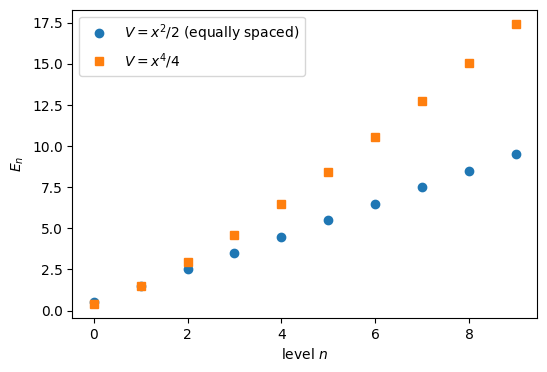

In [11]:
# A quartic (anharmonic) oscillator V = x^4/4 for comparison
E4, psi4 = torch.linalg.eigh(hamiltonian_torch(x, 0.25 * x**4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(10), E[:10], "o", label=r"$V = x^2/2$ (equally spaced)")
ax.plot(range(10), E4[:10], "s", label=r"$V = x^4/4$")
ax.set_xlabel("level $n$"); ax.set_ylabel("$E_n$"); ax.legend()
plt.show()

For the harmonic potential the levels are equally spaced (equation (3)); for the steeper quartic potential the spacing grows with $n$.

<hr/>
## 5. Changing the shape of tensors

Shape operations are frequent in deep-learning code: a batch of images is flattened before a dense layer, a batch dimension is added to a single
sample, the axes of an image are reordered for plotting, two tensors are joined along an axis. This section treats these operations one by one on small tensors
whose entries are $0, 1, 2, \dots$, so that the position of every number can be followed.

To make the result of each operation visible, a small helper draws a 2D tensor as a grid of coloured boxes. The colour of a box depends only on the number in it,
so the same number has the same colour wherever it moves. `np.ndenumerate(a)` yields every index `(i, j)` together with the value `a[i, j]`; the format `:g` prints integers without a decimal point;
the colour of the text switches from white to black above 60 % of the colour scale (a cosmetic choice) so that it stays readable on the light end of the
'viridis' colour map; and `vmax or a.max()` evaluates to `a.max()` when `vmax` is `None`.

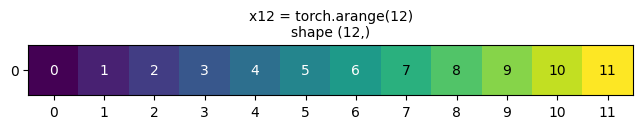

In [12]:
def show_grid(t, title="", ax=None, vmax=None):
    """Draw a 1D or 2D tensor as a grid of boxes with the values stored in them."""
    a = t.detach().numpy()
    a = a.reshape(1, -1) if a.ndim == 1 else a
    if ax is None:
        fig, ax = plt.subplots(figsize=(0.6 * a.shape[1] + 0.6, 0.6 * a.shape[0] + 0.6))
    ax.imshow(a, cmap="viridis", vmin=0, vmax=vmax if vmax is not None else a.max())
    for (i, j), v in np.ndenumerate(a):
        ax.text(j, i, f"{v:g}", ha="center", va="center", color="white" if v < 0.6 * (vmax or a.max()) else "black")
    ax.set_xticks(range(a.shape[1])); ax.set_yticks(range(a.shape[0]))
    ax.set_title(f"{title}\nshape {tuple(t.shape)}", fontsize=10)
    return ax

x12 = torch.arange(12)
show_grid(x12, "x12 = torch.arange(12)")
plt.show()

### 5.1 `reshape` and `view`
`reshape(3, 4)` arranges the 12 numbers into 3 rows of 4, filling **row by row** (the last index changes fastest): the same numbers, a different shape. The total number of elements must not change;
one dimension may be given as `-1`, meaning "whatever is needed". `view` does the same, with one important difference: it never copies the numbers but returns a second way of reading the same memory
(a *view*). Section 5.4 explains what this means and when `view` is not possible.

The last lines of the cell try an impossible shape (15 elements from 12) and use Python's `try`/`except`: the code in the `try` block is run; if it raises an
error of the named type (`RuntimeError`), the program does not stop, the `except` block runs instead and `e` holds the error message. This shows the error
message without interrupting the notebook.

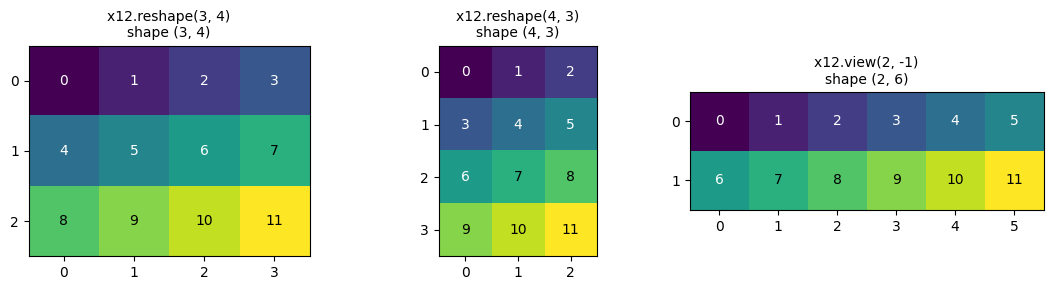

RuntimeError: shape '[5, 3]' is invalid for input of size 12


In [13]:
A = x12.reshape(3, 4)
B43 = x12.reshape(4, 3)
C = x12.view(2, -1)            # -1 is computed: 12 / 2 = 6
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
show_grid(A, "x12.reshape(3, 4)", axes[0], vmax=11)
show_grid(B43, "x12.reshape(4, 3)", axes[1], vmax=11)
show_grid(C, "x12.view(2, -1)", axes[2], vmax=11)
fig.tight_layout(); plt.show()
try:
    x12.reshape(5, 3)
except RuntimeError as e:
    print("RuntimeError:", e)

### 5.2 Strides
In memory, the 12 numbers are always stored one after another in a single row. The shape only tells how to *interpret* this row. The **strides** say how many
positions in memory one has to move to go to the next element along each dimension. For `A = x12.reshape(3, 4)` the strides are `(4, 1)`: the next row starts 4
positions further, the next column 1 position further. The element `A[i, j]` is at memory position `4*i + 1*j`.
`data_ptr()` returns the memory address of the first element of a tensor; equal addresses mean that two tensors read the same memory.

In [14]:
print("A.shape   :", tuple(A.shape))
print("A.stride():", A.stride())
i, j = 2, 1
print(f"A[{i}, {j}] = {A[i, j].item()},  memory position 4*{i} + 1*{j} = {4 * i + j}")
print("A and x12 share the same memory:", A.data_ptr() == x12.data_ptr())

A.shape   : (3, 4)
A.stride(): (4, 1)
A[2, 1] = 9,  memory position 4*2 + 1*1 = 9
A and x12 share the same memory: True


Because `reshape` here only changes the interpretation, `A` and `x12` are two **views** of the same memory: changing an element of one changes the other
(as for NumPy views).

In [15]:
x2 = torch.arange(12)
A2 = x2.reshape(3, 4)
A2[0, 0] = 100
print("x2 after changing A2[0, 0]:", x2)

x2 after changing A2[0, 0]: tensor([100,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11])


### 5.3 Reordering axes
`A.T` (for 2D tensors), `A.transpose(0, 1)` and `A.permute(1, 0)` swap the two axes: row $i$, column $j$ of the result is element $(j, i)$ of `A`.
No number is moved in memory: only the strides are swapped. The result is therefore again a view of the same memory, but its elements are no longer stored
row by row; such a tensor is called **non-contiguous**.

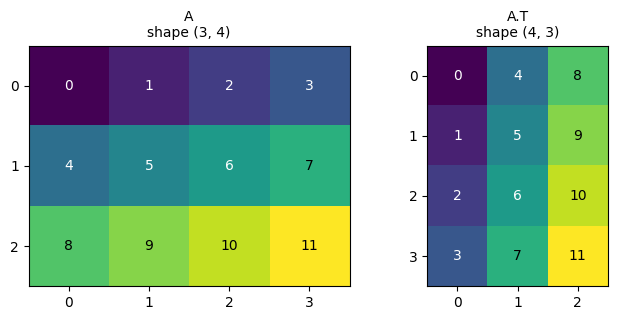

A.stride()  : (4, 1)   contiguous: True
A.T.stride(): (1, 4)   contiguous: False
same memory : True


In [16]:
At = A.T
fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
show_grid(A, "A", axes[0], vmax=11)
show_grid(At, "A.T", axes[1], vmax=11)
fig.tight_layout(); plt.show()
print("A.stride()  :", A.stride(), "  contiguous:", A.is_contiguous())
print("A.T.stride():", At.stride(), "  contiguous:", At.is_contiguous())
print("same memory :", At.data_ptr() == A.data_ptr())

For tensors with more than two axes, `permute` takes the new order of **all** axes, and `transpose(d1, d2)` swaps two of them. Consider a tensor of shape
`(2, 3, 4)`: `permute(2, 0, 1)` puts the old axis 2 first, then old axis 0, then old axis 1, giving shape `(4, 2, 3)`, and element `[k, i, j]` of the result is
element `[i, j, k]` of the original.

In [17]:
T3 = torch.arange(24).reshape(2, 3, 4)
P = T3.permute(2, 0, 1)
print("T3 shape:", tuple(T3.shape), " P = T3.permute(2, 0, 1) shape:", tuple(P.shape))
print("T3[1, 2, 3] =", T3[1, 2, 3].item(), "   P[3, 1, 2] =", P[3, 1, 2].item())
print("T3.transpose(0, 2) shape:", tuple(T3.transpose(0, 2).shape))

T3 shape: (2, 3, 4)  P = T3.permute(2, 0, 1) shape: (4, 2, 3)
T3[1, 2, 3] = 23    P[3, 1, 2] = 23
T3.transpose(0, 2) shape: (4, 3, 2)


### 5.4 Views and contiguity

`t.view(shape)` returns a new tensor object that uses **the same memory** as `t`. Only the description of how to read the memory (the shape
and the strides) is new; not a single number is copied. Two consequences follow: creating a view is instantaneous, even for huge tensors,
and changing an element through the view changes the original, and vice versa.

`y = x12.view(3, 4)` has the same memory address (`data_ptr()`) as `x12`, and a change of one element of `y` appears in `x12`.

In [18]:
x12 = torch.arange(12)                       # 12 numbers stored one after another in memory
y = x12.view(3, 4)                           # the same memory, read as 3 rows of 4
print("y =\n", y)
print("strides of y:", y.stride(), "-> element y[i, j] is at memory position 4*i + j")
print("same memory as x12:", y.data_ptr() == x12.data_ptr())

y[1, 2] = -1                                 # change one element of the view ...
print("x12 after changing y[1, 2]:", x12)    # ... and the original has changed: position 4*1 + 2 = 6

y =
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
strides of y: (4, 1) -> element y[i, j] is at memory position 4*i + j
same memory as x12: True
x12 after changing y[1, 2]: tensor([ 0,  1,  2,  3,  4,  5, -1,  7,  8,  9, 10, 11])


`y[1, 2]` is stored at memory position
$$4\cdot1 + 2 = 6 , \tag{6}$$
and indeed element 6 of `x12` has become $-1$: `y` and `x12` are two ways of reading the same 12 numbers.

A common confusion is to take `view(4, 3)` for the transpose. Both `x.view(4, 3)` and `x.T` (for `x` of shape `(3, 4)`) have shape `(4, 3)`, but they are different tensors.
`view` keeps the order of the numbers in memory and only cuts the row of 12 numbers into pieces of 3; the transpose turns rows into columns.

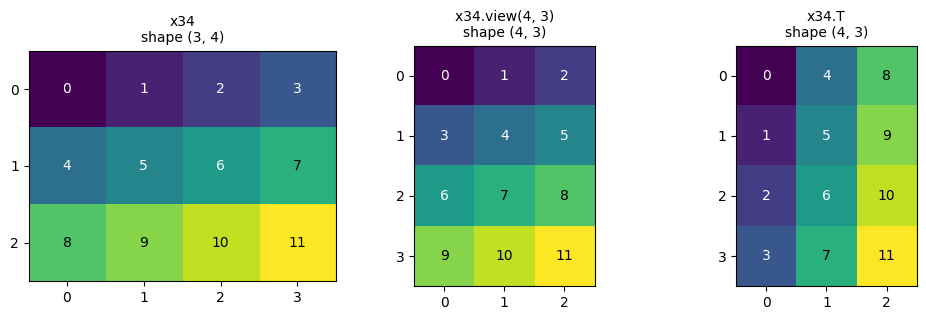

In [19]:
x34 = torch.arange(12).view(3, 4)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
show_grid(x34, "x34", axes[0], vmax=11)
show_grid(x34.view(4, 3), "x34.view(4, 3)", axes[1], vmax=11)
show_grid(x34.T, "x34.T", axes[2], vmax=11)
fig.tight_layout(); plt.show()

In `x34.view(4, 3)` the numbers keep their order $0, 1, 2, \dots$ row by row (first row `0 1 2`); in `x34.T` the first row is the first **column** of `x34`
(`0 4 8`). Using `view` (or `reshape`) where a transpose is meant is a frequent bug: the shapes are right, the numbers are in the wrong places, and no error is raised.

The combination of `view` with a transpose shows when a view is impossible. A view must describe the requested shape with **one stride per axis**, i.e. along each axis the memory positions must be
equally spaced. For `x34.T` (strides `(1, 4)`) this works. Now consider `x34.T.view(-1)`, a flat tensor of 12 elements: reading `x34.T` row by row visits the memory
positions shown below. They are not equally spaced (steps of $+4, +4, -7, +4, \dots$), so no single stride describes them, and `view` refuses.
(Because `x34` contains the numbers $0, \dots, 11$ in memory order, every number is equal to its memory position; this makes the printed positions easy to
compare with the values.)

A few Python details appear in the cell. `[... for i in range(4) for j in range(3)]` is a list comprehension with two loops, in which `j` runs fastest, i.e. the elements are visited row by
row; `.tolist()` converts a tensor into a Python list (for a compact printout); and `np.diff(p)` returns the differences `p[1] - p[0], p[2] - p[1], ...` of
neighbouring elements.

strides of x34.T          : (1, 4)
x34.T read row by row     : [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]
memory positions visited  : [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]
steps between them        : [4, 4, -7, 4, 4, -7, 4, 4, -7, 4, 4]


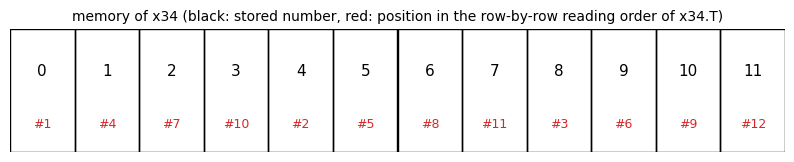

RuntimeError: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.


In [20]:
xT = x34.T                                                    # shape (4, 3), strides (1, 4)
positions = [i * xT.stride(0) + j * xT.stride(1) for i in range(4) for j in range(3)]   # memory position of xT[i, j]
print("strides of x34.T          :", xT.stride())
print("x34.T read row by row     :", xT.reshape(-1).tolist())
print("memory positions visited  :", positions)
print("steps between them        :", np.diff(positions).tolist())

# the same as a picture: the 12 memory cells in a row, numbered by the order in which x34.T reads them
fig, ax = plt.subplots(figsize=(10, 1.6))
# argsort returns the indices that would sort `positions`; since every memory cell occurs exactly once in `positions`,
# order[pos] is the step (0, 1, 2, ...) at which x34.T reads memory cell pos
order = np.argsort(positions)
for pos in range(12):
    ax.add_patch(plt.Rectangle((pos, 0), 1, 1, fill=False))
    ax.text(pos + 0.5, 0.62, f"{x34.reshape(-1)[pos].item()}", ha="center", fontsize=11)        # the number stored there
    ax.text(pos + 0.5, 0.2, f"#{order[pos] + 1}", ha="center", fontsize=9, color="C3")         # when x34.T reads it
ax.set_xlim(0, 12); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("memory of x34 (black: stored number, red: position in the row-by-row reading order of x34.T)", fontsize=10)
plt.show()

try:
    xT.view(-1)
except RuntimeError as e:
    print("RuntimeError:", e)

The red labels jump back and forth through memory, which is exactly what one stride cannot express. There are two ways out, both of which **copy** the data.
`reshape(-1)` returns a view when one is possible and otherwise silently makes a copy, while `contiguous()` makes the copy explicitly (the elements are copied into new memory in row-by-row order), after which `view` works. Both give the numbers in the reading order of `x34.T`, and neither result shares memory with `x34`.

In [21]:
flat1 = xT.reshape(-1)
flat2 = xT.contiguous().view(-1)
print("xT.reshape(-1)          :", flat1.tolist())
print("xT.contiguous().view(-1):", flat2.tolist())
print("is xT contiguous?            ", xT.is_contiguous(), "   is xT.contiguous() contiguous?", xT.contiguous().is_contiguous())
print("reshape result shares memory with x34:", flat1.data_ptr() == x34.data_ptr(), " (a copy was made)")

xT.reshape(-1)          : [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]
xT.contiguous().view(-1): [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]
is xT contiguous?             False    is xT.contiguous() contiguous? True
reshape result shares memory with x34: False  (a copy was made)


In practice, `reshape` is the default choice, because it always works. `view` is used when sharing memory is intended (or to make sure no copy happens), and an error is to be expected
after `transpose`/`permute`. Neither `view` nor `reshape` reorders the numbers: for a transpose use `.T`, `transpose` or `permute`.

### 5.5 Axes of length 1
Many functions expect a particular number of axes. `unsqueeze(d)` inserts an axis of length 1 at position `d`, indexing with `None` does the same, and
`squeeze(d)` removes an axis of length 1. Three situations are typical. A single sample of shape `(n_in,)` needs a batch axis to enter a layer, and `x.unsqueeze(0)` has shape `(1, n_in)`.
A network output of shape `(B, 1)` is turned into `(B,)` with `squeeze(1)`. A 1D grid of shape `(N,)` becomes a batch of 1D inputs `(N, 1)` with `unsqueeze(1)` or `x[:, None]`.

The last lines of the cell use `nn.Linear(4, 2)`, a dense layer mapping 4 inputs to 2 outputs. It is introduced in Section 6 and is used here only to show
that a layer expects a batch axis.

In [22]:
v = torch.arange(4.0)                           # shape (4,)
print("v                 :", tuple(v.shape))
print("v.unsqueeze(0)    :", tuple(v.unsqueeze(0).shape), "  = v[None, :]", tuple(v[None, :].shape))
print("v.unsqueeze(1)    :", tuple(v.unsqueeze(1).shape), "  = v[:, None]", tuple(v[:, None].shape))
out = torch.zeros(5, 1)
print("out               :", tuple(out.shape), " -> out.squeeze(1):", tuple(out.squeeze(1).shape))
print("squeeze() without argument removes ALL axes of length 1:", tuple(torch.zeros(1, 3, 1).squeeze().shape))

layer = nn.Linear(4, 2)
sample = torch.arange(4.0)                       # one sample, no batch axis
print("layer(sample.unsqueeze(0)).shape:", tuple(layer(sample.unsqueeze(0)).shape))

v                 : (4,)
v.unsqueeze(0)    : (1, 4)   = v[None, :] (1, 4)
v.unsqueeze(1)    : (4, 1)   = v[:, None] (4, 1)
out               : (5, 1)  -> out.squeeze(1): (5,)
squeeze() without argument removes ALL axes of length 1: (3,)
layer(sample.unsqueeze(0)).shape: (1, 2)


`squeeze()` without an argument is risky: for a batch of size 1 it also removes the batch axis. Giving the axis explicitly, `squeeze(1)`, avoids this.

### 5.6 `flatten` and `unflatten`
`flatten(start_dim)` merges all axes from `start_dim` on into one; `unflatten(dim, sizes)` splits one axis into several. For a batch of images of shape
`(B, 28, 28)`, `flatten(1)` keeps the batch axis and merges the pixels into `(B, 784)` (this is what `nn.Flatten()` does).
The example images are random: `torch.rand` draws numbers uniformly from $[0, 1)$, like pixel intensities, whereas `torch.randn` draws from the standard normal
distribution. `torch.equal(a, b)` is `True` only if the two tensors have the same shape and exactly the same elements.

In [23]:
images = torch.rand(16, 28, 28)
flat = images.flatten(1)                          # keep axis 0 (batch), merge the rest
print("images:", tuple(images.shape), " -> flatten(1):", tuple(flat.shape))
print("flatten() of everything:", tuple(images.flatten().shape))
back = flat.unflatten(1, (28, 28))
print("unflatten(1, (28, 28)):", tuple(back.shape), "  identical to the original:", torch.equal(back, images))

images: (16, 28, 28)  -> flatten(1): (16, 784)
flatten() of everything: (12544,)
unflatten(1, (28, 28)): (16, 28, 28)   identical to the original: True


### 5.7 Image layouts
A colour image is stored as three arrays of the same size, the **channels**: the intensities of red, green and blue (RGB) of every pixel, here numbers
in $[0, 1]$. PyTorch stores a batch of colour images as `(batch, channels, height, width)`, i.e. `(B, C, H, W)`; Matplotlib's `imshow` expects one image as `(height, width, channels)`.
The conversion is a `permute`. Below, a batch of 2 synthetic RGB images of $32\times48$ pixels: in the first one the red channel grows from left to right and
the blue channel from top to bottom; the second image is `1 - img`, whose green channel equals 1 everywhere. Two operations explained in the next sections are
used to build them: `expand` (5.9) repeats a row or column to fill the $H\times W$ array, and `stack` (5.8) joins the three channels along a new first axis.

img_batch: (2, 3, 32, 48) (B, C, H, W)


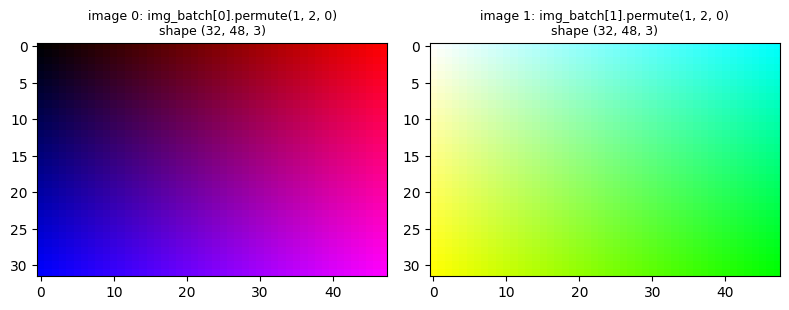

In [24]:
H, W = 32, 48
red = torch.linspace(0, 1, W).expand(H, W)               # grows along the width
blue = torch.linspace(0, 1, H)[:, None].expand(H, W)     # grows along the height
green = torch.zeros(H, W)
img = torch.stack([red, green, blue])                     # shape (3, H, W): channels first
img_batch = torch.stack([img, 1 - img])                   # shape (2, 3, H, W): a batch of 2 images
print("img_batch:", tuple(img_batch.shape), "(B, C, H, W)")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for k, ax in enumerate(axes):
    ax.imshow(img_batch[k].permute(1, 2, 0))              # (C, H, W) -> (H, W, C) for imshow
    ax.set_title(f"image {k}: img_batch[{k}].permute(1, 2, 0)\nshape {tuple(img_batch[k].permute(1, 2, 0).shape)}", fontsize=9)
fig.tight_layout(); plt.show()

### 5.8 Joining tensors
Tensors are joined in two ways. `torch.cat([a, b], dim=d)` joins them **along an existing axis**, so all other axes must agree.
`torch.stack([a, b], dim=d)` creates a **new axis** at position `d`, so the tensors must have identical shapes.

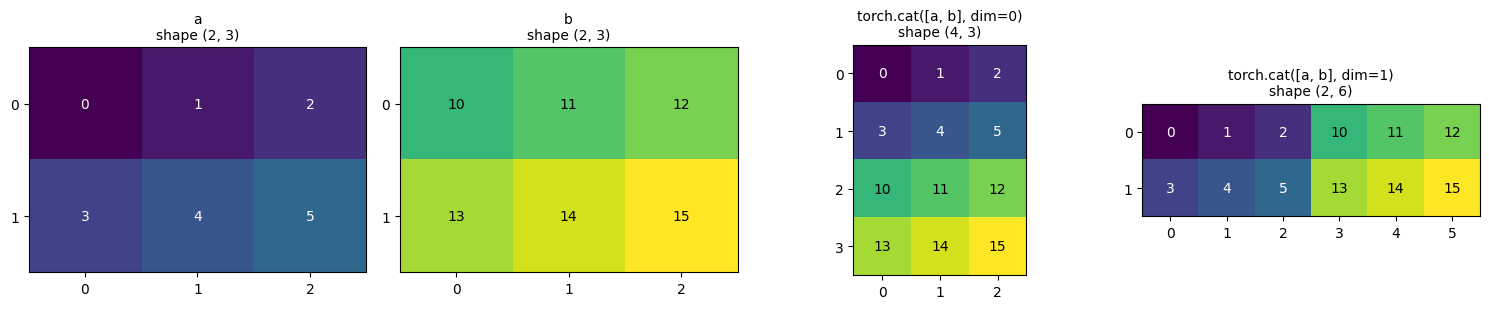

torch.stack([a, b], dim=0).shape: (2, 2, 3)
torch.stack([a, b], dim=2).shape: (2, 3, 2)


In [25]:
a = torch.arange(6).reshape(2, 3)
b = 10 + torch.arange(6).reshape(2, 3)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
show_grid(a, "a", axes[0], vmax=15); show_grid(b, "b", axes[1], vmax=15)
show_grid(torch.cat([a, b], dim=0), "torch.cat([a, b], dim=0)", axes[2], vmax=15)
show_grid(torch.cat([a, b], dim=1), "torch.cat([a, b], dim=1)", axes[3], vmax=15)
fig.tight_layout(); plt.show()
print("torch.stack([a, b], dim=0).shape:", tuple(torch.stack([a, b], dim=0).shape))
print("torch.stack([a, b], dim=2).shape:", tuple(torch.stack([a, b], dim=2).shape))

### 5.9 Repeating values and broadcasting
`expand` repeats a tensor along axes of length 1 **without copying** (it sets the stride of these axes to 0); it can also add new axes in front, e.g. a vector of
shape `(W,)` expanded to `(H, W)`. `repeat` makes real copies. In arithmetic,
broadcasting performs the expansion automatically. A typical use is the computation of all pairwise differences of $N$ points in 2D. The points `(N, 2)` are
turned into `(N, 1, 2)` and `(1, N, 2)`; their difference broadcasts to `(N, N, 2)`, with element `diff[i, j]` equal to the vector $\mathbf p_i - \mathbf p_j$.
`diff.norm(dim=2)` computes the length $\sqrt{d_x^2 + d_y^2}$ of every such vector, i.e. along the last axis, so that `dist[i, j]` is the distance between points $i$ and $j$.

In [26]:
row = torch.arange(3).reshape(1, 3)
e = row.expand(4, 3)
r = row.repeat(4, 1)
print("expand:", tuple(e.shape), "strides", e.stride(), " shares memory:", e.data_ptr() == row.data_ptr())
print("repeat:", tuple(r.shape), "strides", r.stride(), " shares memory:", r.data_ptr() == row.data_ptr())

pts = torch.tensor([[0.0, 0.0], [3.0, 0.0], [0.0, 4.0]])          # N = 3 points: a 3-4-5 right triangle, so the
                                                                   # distances are integers and easy to check
diff = pts.unsqueeze(1) - pts.unsqueeze(0)                         # (3, 1, 2) - (1, 3, 2) -> (3, 3, 2)
dist = diff.norm(dim=2)                                            # length along the last axis -> (3, 3)
print("pairwise distances:\n", dist)

expand: (4, 3) strides (0, 1)  shares memory: True
repeat: (4, 3) strides (3, 1)  shares memory: False
pairwise distances:
 tensor([[0., 3., 4.],
        [3., 0., 5.],
        [4., 5., 0.]])


### 5.10 Batched matrix products
The operator `@` works on batches: for `M` of shape `(B, n, m)` and `N` of shape `(B, m, k)` it computes `B` matrix products at once, giving `(B, n, k)`.
A batch of vectors `(B, m)` is multiplied by a batch of matrices `(B, n, m)` after adding an axis: `v.unsqueeze(2)` of shape `(B, m, 1)` is a batch of column vectors, i.e. of $m\times1$ matrices, `M @ v.unsqueeze(2)` has shape
`(B, n, 1)`, and `(M @ v.unsqueeze(2)).squeeze(2)` removes the column axis again, giving `(B, n)`.

In [27]:
torch.manual_seed(0)
M = torch.randn(5, 3, 4)                 # 5 matrices of shape 3 x 4
Nm = torch.randn(5, 4, 2)                # 5 matrices of shape 4 x 2
v_batch = torch.randn(5, 4)              # 5 vectors of length 4
print("M @ Nm                               :", tuple((M @ Nm).shape))
print("(M @ v_batch.unsqueeze(2)).squeeze(2):", tuple((M @ v_batch.unsqueeze(2)).squeeze(2).shape))

M @ Nm                               : (5, 3, 2)
(M @ v_batch.unsqueeze(2)).squeeze(2): (5, 3)


### 5.11 Tensors, indices and contractions

In this course a tensor is an array of numbers whose elements are labelled by indices: a scalar $s$ has no index, a vector
$v_i$ one, a matrix $A_{ij}$ two, a three-index array $T_{ijk}$ three. Each index runs over one axis of the array; the range of an index is the length of that axis.
A PyTorch tensor of shape `(2, 3, 4)` is $T_{ijk}$ with $i$ from 1 to 2, $j$ from 1 to 3 and $k$ from 1 to 4; in PyTorch the same indices run from 0, i.e. `T[0..1, 0..2, 0..3]`.
The number of indices is called the **rank** (or order) of the tensor; this is not the rank of a matrix in linear algebra. In PyTorch it is `t.ndim`.

The simplest product of two vectors is the inner (scalar) product. For two vectors $u$ and $v$ of the same length $m$,
$$s = \sum_{i=1}^{m} u_i\, v_i, \qquad (m)\cdot(m) \;\to\; \text{a scalar}. \tag{7}$$
The two vectors share the index $i$, which is summed: nothing is left, and the result is a single number. Both vectors must have the same length, because they
share the index. This is the simplest **contraction**, and the two products below are built from it.

A matrix acts on a vector in the same way. For a matrix $A$ of shape $n\times m$ and a vector $v$ of length $m$,
$$w_i = \sum_{j=1}^{m} A_{ij}\, v_j, \qquad i = 1, \dots, n . \tag{8}$$
Element $w_i$ is the scalar product of row $i$ of $A$ with $v$. The summed index $j$ belongs to both factors and must therefore have the **same range** in both:
the number of columns of $A$ must equal the length of $v$. The result keeps the free index $i$:
$$(n\times m)\cdot(m) \;\to\; (n). \tag{9}$$

The product of two matrices follows the same pattern. For $A$ of shape $n\times m$ and $B$ of shape $m\times p$,
$$C_{ik} = \sum_{j=1}^{m} A_{ij}\, B_{jk}, \qquad (n\times m)\cdot(m\times p) \;\to\; (n\times p). \tag{10}$$
Element $C_{ik}$ is the scalar product of row $i$ of $A$ with column $k$ of $B$. The "inner" dimensions (both $m$) are summed and disappear; the "outer" ones
($n$ and $p$) remain. The matrices need not be square: only the summed index must match. In general the products $AB$ and $BA$ differ, even for square matrices; for
rectangular matrices $BA$ may not even be defined (it requires as many columns of $B$ as rows of $A$).

The opposite case is the outer product. If no index is summed, two vectors give a matrix,
$$M_{ij} = u_i v_j , \qquad (n)\cdot(m) \;\to\; (n\times m), \tag{11}$$
and the vectors may have different lengths.

In [28]:
torch.manual_seed(0)
u, w = torch.randn(3), torch.randn(3)
print("inner product u.w:  torch.dot", round(torch.dot(u, w).item(), 5), "| u @ w", round((u @ w).item(), 5),
      "| sum_i u_i w_i", round((u * w).sum().item(), 5), "| einsum", round(torch.einsum("i,i->", u, w).item(), 5))
print("outer product shape:", tuple(torch.outer(u, torch.randn(5)).shape), " (vectors of lengths 3 and 5)")

A23 = torch.randn(2, 3)        # n x m = 2 x 3 (rectangular)
v3 = torch.randn(3)            # length m = 3
B34 = torch.randn(3, 4)        # m x p = 3 x 4

print("A23 @ v3  :", tuple(A23.shape), "x", tuple(v3.shape), "->", tuple((A23 @ v3).shape))
print("A23 @ B34 :", tuple(A23.shape), "x", tuple(B34.shape), "->", tuple((A23 @ B34).shape))
# PyTorch counts indices from 0: element 0 of the result is the formula's w_1
print("first element by the formula, sum_j A_0j v_j =", (A23[0] * v3).sum().item(), "   (A23 @ v3)[0] =", (A23 @ v3)[0].item())

try:
    B34 @ A23                  # (3 x 4) x (2 x 3): the inner dimensions 4 and 2 differ
except RuntimeError as e:
    print("B34 @ A23 fails:", e)
print("A23 @ A23.T :", tuple((A23 @ A23.T).shape), "   A23.T @ A23 :", tuple((A23.T @ A23).shape), " <- both defined, different shapes")

inner product u.w:  torch.dot 4.24143 | u @ w 4.24143 | sum_i u_i w_i 4.24143 | einsum 4.24143
outer product shape: (3, 5)  (vectors of lengths 3 and 5)
A23 @ v3  : (2, 3) x (3,) -> (2,)
A23 @ B34 : (2, 3) x (3, 4) -> (2, 4)
first element by the formula, sum_j A_0j v_j = -0.8288600444793701    (A23 @ v3)[0] = -0.8288600444793701
B34 @ A23 fails: mat1 and mat2 shapes cannot be multiplied (3x4 and 2x3)
A23 @ A23.T : (2, 2)    A23.T @ A23 : (3, 3)  <- both defined, different shapes


The matrix-vector and matrix-matrix products are the simplest examples of one general operation, the **tensor contraction**. A contraction sums over a pair of indices
with the same range: one index from each of two tensors (as $j$ above), or two indices of the same tensor (as in the trace of a matrix). Each contracted pair
removes two indices, so
$$\text{rank of the result} = \text{sum of the ranks of the factors} - 2\times(\text{number of contracted pairs}). \tag{12}$$
This rule holds when every index either appears once (a free index) or appears exactly twice and is summed. An index that is shared but **not** summed (a batch
index, or an element-wise product, see 5.12) lowers the rank by one instead of two.
For the products above,
$$\begin{aligned} &\text{inner product: } 1 + 1 - 2 = 0 \ \text{(a scalar)}, && \text{matrix times vector: } 2 + 1 - 2 = 1, \\ &\text{matrix times matrix: } 2 + 2 - 2 = 2, && \text{outer product: } 1 + 1 - 0 = 2 . \end{aligned} \tag{13}$$
With more indices the same operation reads, for example,
$$C_{il} = \sum_{j}\sum_{k} T_{ijk}\, S_{jkl}, \qquad (n\times m\times r)\cdot(m\times r\times p)\;\to\;(n\times p),\qquad \text{rank } 3 + 3 - 4 = 2 , \tag{14}$$
two pairs of indices ($j$ and $k$) being contracted at once. Contractions of this kind are common in physics: the expectation value
$$\langle\psi|H|\psi\rangle = \sum_{ij}\psi_i^* H_{ij}\psi_j , \tag{15}$$
the stress tensor acting on a normal vector, tensor-network states of quantum many-body systems.

Because sums over repeated indices are so frequent, Einstein proposed to omit the summation sign: in the **Einstein summation convention** an index that appears
twice in a product is summed. The formulas above become
$$w_i = A_{ij}v_j, \qquad C_{ik} = A_{ij}B_{jk}, \qquad s = u_iv_i, \qquad C_{il} = T_{ijk}S_{jkl} . \tag{16}$$
Indices that appear once (here $i$, $k$, $l$) are *free*: they label the elements of the result.

### 5.12 `einsum`
`torch.einsum` takes such a formula as a string and is the summation convention in code. For the matrix product $C_{ik}$ of equation (16) one writes

```python
C = torch.einsum("ij,jk->ik", A, B)
```

The string is read with three rules. First, left of `->` there is one group of letters per input tensor, separated by commas, with **one letter per axis**. `"ij,jk"` says that the first tensor has two axes called
`i` and `j`, and the second two axes called `j` and `k`; the number of letters must equal the number of axes of the tensor.
Second, the same letter in different inputs means that these axes are **the same index**: they must have equal lengths, and the elements are multiplied with
matching values of this index.
Third, right of `->` stand the free indices of the result, in this order. Every letter that appears on the left but **not on the right is summed over**.
Unlike in the pure Einstein convention, the output is given explicitly; this also allows keeping a repeated index (no sum) or choosing the order of the axes.

In words, `"ij,jk->ik"` means: for every pair $(i, k)$, multiply $A_{ij}B_{jk}$ and sum over $j$, because $j$ does not appear in the output.

The rules can be checked by computing the same quantity with explicit loops: one loop per letter, the product of the indexed elements in the innermost loop,
and accumulation into the output elements labelled by the letters after `->`. The comparisons use `torch.allclose(a, b)`, which checks equality up to the
rounding errors of floating-point arithmetic: element by element it applies the test of equation (2), with the same default tolerances. In `float32` a sum computed in a different order (loops, `@`, `einsum`) differs in the last digits, i.e. by
about $10^{-7}$ times the size of the terms. For elements that happen to be close to zero the relative part $\text{rtol}\,|b|$ is then tiny and the default
$\text{atol}$ can be too strict, so several later cells set `atol=1e-6` (or `1e-5` for larger sums) as a safeguard against such false alarms.

In [29]:
torch.manual_seed(1)
a = torch.randn(2, 3)          # axes i (length 2), j (length 3)
b = torch.randn(3, 4)          # axes j (length 3), k (length 4)

# einsum
c_einsum = torch.einsum("ij,jk->ik", a, b)

# the same with explicit loops: one loop per letter, sum over j because j is missing after '->'
c_loops = torch.zeros(2, 4)
for i in range(2):
    for k in range(4):
        for j in range(3):
            c_loops[i, k] += a[i, j] * b[j, k]

print("einsum == loops :", torch.allclose(c_einsum, c_loops))
print("einsum == a @ b :", torch.allclose(c_einsum, a @ b))

einsum == loops : True
einsum == a @ b : True


The basic operations of linear algebra all have short `einsum` strings. Each string, read with the three rules above, is checked below against the corresponding standard PyTorch function.

| string | formula | meaning |
|---|---|---|
| `"i,i->"` | $\sum_i u_i v_i$ | scalar product (`i` is summed, nothing is left: a number) |
| `"i,j->ij"` | $u_i v_j$ | outer product (nothing summed) |
| `"i,i->i"` | $u_i v_i$ | element-wise product (`i` kept in the output, so not summed) |
| `"ij,j->i"` | $\sum_j A_{ij} v_j$ | matrix times vector |
| `"ij,jk->ik"` | $\sum_j A_{ij} B_{jk}$ | matrix times matrix |
| `"ij->ji"` | $A_{ji}$ | transpose (only the order of the output letters changes) |
| `"ii->"` | $\sum_i A_{ii}$ | trace (a repeated letter in one input selects the diagonal) |
| `"ii->i"` | $A_{ii}$ | diagonal |
| `"ij->i"` | $\sum_j A_{ij}$ | sum over the second axis (row sums) |
| `"ij,ij->"` | $\sum_{ij} A_{ij}B_{ij}$ | Frobenius scalar product of two matrices |

In [30]:
torch.manual_seed(2)
u, w = torch.randn(4), torch.randn(4)
Asq, Bm = torch.randn(4, 4), torch.randn(4, 3)

checks = [
    ("i,i->     scalar product  ", torch.einsum("i,i->", u, w),        torch.dot(u, w)),
    ("i,j->ij   outer product   ", torch.einsum("i,j->ij", u, w),      torch.outer(u, w)),
    ("i,i->i    element-wise    ", torch.einsum("i,i->i", u, w),       u * w),
    ("ij,j->i   matrix-vector   ", torch.einsum("ij,j->i", Asq, u),    Asq @ u),
    ("ij,jk->ik matrix-matrix   ", torch.einsum("ij,jk->ik", Asq, Bm), Asq @ Bm),
    ("ij->ji    transpose       ", torch.einsum("ij->ji", Asq),        Asq.T),
    ("ii->      trace           ", torch.einsum("ii->", Asq),          torch.trace(Asq)),
    ("ii->i     diagonal        ", torch.einsum("ii->i", Asq),         torch.diagonal(Asq)),
    ("ij->i     row sums        ", torch.einsum("ij->i", Asq),         Asq.sum(dim=1)),
    ("ij,ij->   Frobenius       ", torch.einsum("ij,ij->", Asq, Asq),  (Asq * Asq).sum()),
]
for name, with_einsum, reference in checks:
    print(f"{name}: result shape {str(tuple(with_einsum.shape)):8s} agrees: {torch.allclose(with_einsum, reference)}")

i,i->     scalar product  : result shape ()       agrees: True
i,j->ij   outer product   : result shape (4, 4)   agrees: True
i,i->i    element-wise    : result shape (4,)     agrees: True
ij,j->i   matrix-vector   : result shape (4,)     agrees: True
ij,jk->ik matrix-matrix   : result shape (4, 3)   agrees: True
ij->ji    transpose       : result shape (4, 4)   agrees: True
ii->      trace           : result shape ()       agrees: True
ii->i     diagonal        : result shape (4,)     agrees: True
ij->i     row sums        : result shape (4,)     agrees: True
ij,ij->   Frobenius       : result shape ()       agrees: True


A letter that appears in the output is never summed. If it appears in several inputs, their elements are multiplied with matching values of
this index; such an index labels independent copies of the same operation, a **batch index**. `"bij,bjk->bik"` is a matrix product for every `b` separately.
In `"bi,ij->bj"` the letter `b` belongs to the first input only: the same matrix is applied to every vector of the batch.

In [31]:
torch.manual_seed(3)
Mb = torch.randn(5, 3, 4)          # b, i, j
Nb = torch.randn(5, 4, 2)          # b, j, k
X = torch.randn(5, 4)              # b, i : a batch of 5 vectors of length 4
W = torch.randn(4, 6)              # i, j : one matrix for all of them

print("bij,bjk->bik :", torch.allclose(torch.einsum("bij,bjk->bik", Mb, Nb), Mb @ Nb))
print("bi,ij->bj    :", torch.allclose(torch.einsum("bi,ij->bj", X, W), X @ W))
print("bi,bi->b     :", torch.allclose(torch.einsum("bi,bi->b", X, X), (X * X).sum(dim=1)), " (one scalar product per batch element)")

bij,bjk->bik : True
bi,ij->bj    : True
bi,bi->b     : True  (one scalar product per batch element)


With more axes, the same three rules give general tensor contractions. In `"ijk,jkl->il"` the letters `j` and `k` appear in both inputs and not in the output,
so both are summed, as in equation (14). Without `einsum` this needs a reshape that merges the two contracted axes into one, followed by a matrix product.

In [32]:
torch.manual_seed(4)
T = torch.randn(2, 3, 4)        # i, j, k
S = torch.randn(3, 4, 5)        # j, k, l

C_einsum = torch.einsum("ijk,jkl->il", T, S)
C_reshape = T.reshape(2, 12) @ S.reshape(12, 5)        # merge (j, k) into one axis of length 12 on both sides
C_loops = torch.zeros(2, 5)
for i in range(2):
    for l in range(5):
        for j in range(3):
            for k in range(4):
                C_loops[i, l] += T[i, j, k] * S[j, k, l]
print("shape:", tuple(C_einsum.shape))
print("einsum == reshape + @ :", torch.allclose(C_einsum, C_reshape, atol=1e-6))
print("einsum == loops       :", torch.allclose(C_einsum, C_loops, atol=1e-6))

shape: (2, 5)
einsum == reshape + @ : True
einsum == loops       : True


Expectation values in quantum mechanics are a natural physics application. For a state vector $\psi$ (normalised, real here for simplicity) and a Hamiltonian matrix $H$, equation (15) with real components,
$$\langle\psi|H|\psi\rangle = \sum_{ij}\psi_i H_{ij}\psi_j , \tag{17}$$
is `"i,ij,j->"`: three inputs, all letters summed. For a batch of states $\psi_{bi}$ the batch letter is kept:
`"bi,ij,bj->b"` gives one expectation value per state. We use the grid Hamiltonian of the harmonic oscillator from Section 4 and its first three eigenstates,
whose energies are about 0.5, 1.5 and 2.5. Since `eigh` returns normalised eigenvectors,
$$H\psi_b = E_b\psi_b, \qquad \sum_i \psi_{bi}^2 = 1 , \tag{18}$$
the expectation values must equal the eigenvalues. `eigh` returns the eigenvectors as the columns of `psi_ho`, so `psi_ho[:, :3]` holds the three lowest states as columns and the
transpose `.T` puts them into rows, one state per value of `b`.

In [33]:
x_grid = torch.linspace(-6, 6, 400, dtype=torch.float64)
H_ho = hamiltonian_torch(x_grid, 0.5 * x_grid**2)                    # Section 4
E_ho, psi_ho = torch.linalg.eigh(H_ho)
states = psi_ho[:, :3].T                                             # three eigenstates as rows: shape (3, 400), axes b, i

single = torch.einsum("i,ij,j->", states[0], H_ho, states[0])         # one state
E_batch = torch.einsum("bi,ij,bj->b", states, H_ho, states)          # three states at once
print("<psi_0|H|psi_0>      :", round(single.item(), 4))
print("<psi_b|H|psi_b>, b=0,1,2:", E_batch.numpy().round(4))
print("eigenvalues from eigh   :", E_ho[:3].numpy().round(4))

<psi_0|H|psi_0>      : 0.5
<psi_b|H|psi_b>, b=0,1,2: [0.5    1.4999 2.4996]
eigenvalues from eigh   : [0.5    1.4999 2.4996]


An `einsum` string never contains the **lengths** of the axes: `"ij,jk->ik"` works for matrices of
any sizes $n\times m$ and $m\times p$. What a string fixes is the **number** of axes of every input. Two tools handle tensors whose number of axes is not known
beforehand.

The first is the ellipsis `...`, which stands for "any number of axes here, possibly none". The letters then describe only the axes that take part in the operation, and all
other axes are carried along unchanged. The string `"...i,ji->...j"` applies a matrix $W_{ji}$ to the **last** axis of a tensor of any rank, e.g. shapes `(4,)`, `(B, 4)` or `(B, T, 4)`; this is what
`nn.Linear` does with its input (apart from adding the bias). Similarly, `"...ij,...jk->...ik"` gives matrix products with any number of batch axes in front,
and `"...ii->..."` the trace over the last two axes, whatever comes before them.

The comparisons in the cell address axes with **negative numbers**, which count from the end: $-1$ is the last axis, $-2$ the one before it. This addresses the
last axes independently of how many axes stand in front of them, the same idea as `...`. `Sq.diagonal(dim1=-2, dim2=-1)` takes the diagonals of the matrices
formed by the last two axes, and `.sum(-1)` sums over the last axis. (In `reshape` and `view`, by contrast, $-1$ means "size to be computed".)

In [34]:
torch.manual_seed(6)
W = torch.randn(3, 4)                                 # maps the last axis from length 4 to length 3
for shape in [(4,), (5, 4), (2, 5, 4)]:               # tensors of rank 1, 2 and 3
    X = torch.randn(shape)
    out = torch.einsum("...i,ji->...j", X, W)         # one string for all ranks
    print(f"input {str(shape):10s} -> output {str(tuple(out.shape)):10s} same as X @ W.T: {torch.allclose(out, X @ W.T, atol=1e-6)}")

Mb = torch.randn(2, 6, 3, 4); Nb = torch.randn(2, 6, 4, 5)       # two batch axes in front
print("...ij,...jk->...ik :", tuple(torch.einsum("...ij,...jk->...ik", Mb, Nb).shape),
      " same as @:", torch.allclose(torch.einsum("...ij,...jk->...ik", Mb, Nb), Mb @ Nb, atol=1e-6))
Sq = torch.randn(2, 6, 3, 3)
print("...ii->...         :", tuple(torch.einsum("...ii->...", Sq).shape),
      " same as traces:", torch.allclose(torch.einsum("...ii->...", Sq), Sq.diagonal(dim1=-2, dim2=-1).sum(-1)))

input (4,)       -> output (3,)       same as X @ W.T: True
input (5, 4)     -> output (5, 3)     same as X @ W.T: True
input (2, 5, 4)  -> output (2, 5, 3)  same as X @ W.T: True
...ij,...jk->...ik : (2, 6, 3, 5)  same as @: True
...ii->...         : (2, 6)  same as traces: True


The second tool is to build the string in code. Sometimes the axis that takes part in the contraction is only known when the program runs, e.g. "apply the matrix $M$ to axis
$k$ of a tensor $T$ with $N$ axes", where $N$ and $k$ are variables. The string is then assembled from letters: one letter per axis of $T$, the letter of axis $k$
is shared with $M$, and in the output it is replaced by a new letter:
$$T'_{a_1 \dots a_{k-1}\, b\, a_{k+1} \dots a_N} = \sum_{a_k} M_{b\, a_k}\, T_{a_1 \dots a_k \dots a_N}. \tag{19}$$
This operation appears, for example, when an operator acts on one index of a many-index object (in quantum mechanics: a one-qubit gate acting on the state of
$N$ qubits, stored as a tensor with $N$ axes of length 2).

The cell uses a few Python details: the module `string` provides `string.ascii_lowercase`, the string `'abcdefghijklmnopqrstuvwxyz'`; a string is sliced like a list
(`letters[:4]` is `'abcd'`); `f"..."` inserts the values of the expressions in braces; and a function can return several values separated by commas, which the
caller unpacks into several variables (`out, spec = ...`).

In [35]:
import string

def apply_along_axis(M, T, k):
    """Contract the matrix M (shape (n_out, n_k)) with axis k of the tensor T; the new axis stays at position k."""
    letters = string.ascii_lowercase                 # 'abcdefghijklmnopqrstuvwxyz'
    t_idx = letters[:T.ndim]                         # one letter per axis of T, e.g. 'abcd'
    new = letters[T.ndim]                            # an unused letter for the output axis
    out_idx = t_idx[:k] + new + t_idx[k + 1:]        # axis k replaced by the new letter
    spec = f"{new}{t_idx[k]},{t_idx}->{out_idx}"     # e.g. 'ec,abcd->abed' for k = 2
    return torch.einsum(spec, M, T), spec

torch.manual_seed(7)
T = torch.randn(2, 3, 4, 5)                          # N = 4 axes
M = torch.randn(6, 4)                                # acts on an axis of length 4
out, spec = apply_along_axis(M, T, k=2)
# check: move axis k to the end, multiply with M^T, move the new axis back to position k
reference = (T.movedim(2, -1) @ M.T).movedim(-1, 2)
print("generated string:", spec)
print("result shape    :", tuple(out.shape), "  same as movedim + @:", torch.allclose(out, reference, atol=1e-6))

generated string: ec,abcd->abed
result shape    : (2, 3, 6, 5)   same as movedim + @: True


`movedim(source, destination)` moves one axis to another position (a `permute` that changes only one axis). The same contraction can also be done with
`torch.tensordot(M, T, dims=([1], [k]))`, which contracts axis 1 of `M` with axis `k` of `T` and puts the remaining axes of `M` first; `einsum` has the advantage
that the order of the output axes is written explicitly.

To sum up the rules of `einsum`: one letter per axis; equal letters are the same index; letters missing after `->` are summed; letters kept after `->` are not summed
(if they appear in several inputs they act as batch indices); the order of the letters after `->` is the order of the output axes. `...` stands for any number of
further axes, so that one string works for tensors of different rank; strings can also be assembled in code. When an operation has a
standard function (`@`, `.T`, `sum`), that function is usually at least as fast; `einsum` is most useful when several axes are contracted at once or when the index
notation makes the code easier to compare with a formula.

### 5.13 Summary of shape operations

| operation | what it does | copies data? | typical use |
|---|---|---|---|
| `reshape(shape)` | new shape, same order of elements | only if necessary | general reshaping |
| `view(shape)` | new shape, same order of elements | never (error if impossible) | reshaping when a view is required |
| `.T`, `transpose(d1, d2)` | swaps two axes | no (non-contiguous result) | matrix transpose |
| `permute(order)` | reorders all axes | no (non-contiguous result) | between `(B, C, H, W)` and `(B, H, W, C)` |
| `contiguous()` | stores the elements row by row | yes, if non-contiguous | before `view` |
| `unsqueeze(d)`, `x[:, None]` | inserts an axis of length 1 | no | adding a batch or feature axis |
| `squeeze(d)` | removes an axis of length 1 | no | `(B, 1)` to `(B,)` |
| `flatten(d)`, `unflatten(d, sizes)` | merges / splits axes | as `reshape` | images to vectors for dense layers |
| `cat(list, dim)` | joins along an existing axis | yes | concatenating batches or features |
| `stack(list, dim)` | joins along a new axis | yes | building a batch from samples |
| `expand(shape)` | repeats along axes of length 1 | no | explicit broadcasting |
| `repeat(counts)` | repeats along any axes | yes | tiling |
| `einsum(string, ...)` | products and sums in index notation (`...` = any further axes) | usually; pure reorderings and diagonals return views | contractions over several axes, batched products |

<hr/>
## 6. Layers and activation functions

`nn.Linear(n_in, n_out)` is the dense (fully connected) layer
$$\mathbf z \;\mapsto\; \mathbf W\mathbf z + \mathbf b . \tag{20}$$
It creates and **randomly initialises** its own parameters `weight` (shape `(n_out, n_in)`) and `bias` (shape `(n_out,)`): by default all of them are drawn
uniformly from $[-1/\sqrt{n_{\rm in}},\, 1/\sqrt{n_{\rm in}}]$. The factor $1/\sqrt{n_{\rm in}}$ keeps the outputs of the layer of order one, independently of
the number of inputs (the reason is given in Section 7). The input is a batch of shape `(B, n_in)`, and the output has shape `(B, n_out)`.

In the printout, `.data` gives the bare numbers of a parameter without its gradient bookkeeping; it is used here only for a shorter printout. In computations
`.data` should be avoided, because changes made through it are invisible to autograd; the safe alternatives are `.detach()` and `torch.no_grad()`.

In [36]:
torch.manual_seed(0)
layer = nn.Linear(in_features=3, out_features=2)
print(layer)
print("weight:", layer.weight.shape, "\n", layer.weight.data)
print("weight.requires_grad:", layer.weight.requires_grad)
print("bias  :", layer.bias.shape, layer.bias.data)

Z = torch.randn(5, 3)            # batch of 5 inputs with 3 features each
out = layer(Z)                   # calling the layer = forward pass
print("output shape:", out.shape)

# check: it is really Z @ W^T + b
print("same as manual:", torch.allclose(out, Z @ layer.weight.T + layer.bias))

Linear(in_features=3, out_features=2, bias=True)
weight: torch.Size([2, 3]) 
 tensor([[-0.0043,  0.3097, -0.4752],
        [-0.4249, -0.2224,  0.1548]])
weight.requires_grad: True
bias  : torch.Size([2]) tensor([-0.0114,  0.4578])
output shape: torch.Size([5, 2])
same as manual: True


`layer.weight.requires_grad` is `True`: these are trainable parameters, and PyTorch will compute gradients with respect to them.

Activation functions exist both as layers (`nn.Tanh()`, `nn.ReLU()`, ...) and as functions (`torch.tanh`, `torch.relu`, ...). The six plotted below are (in the plots, $\sigma$ denotes a generic activation function)

| name | formula |
|---|---|
| Sigmoid | $1/(1 + e^{-z})$ |
| Tanh | $\tanh z$ |
| ReLU | $\max(0, z)$ |
| LeakyReLU($\alpha$) | $z$ for non-negative $z$, $\alpha z$ for negative $z$; the slope $\alpha$ is a free choice (0.01 is PyTorch's default, 0.1 is used here to make it visible) |
| GELU | $z\,\Phi(z)$, with $\Phi$ the cumulative distribution function of the standard normal distribution |
| Softplus | $\ln(1 + e^{z})$, a smooth version of ReLU |

In the code, `acts` is a dictionary from names to layers; `acts.items()` yields the pairs (name, layer). `axes.flatten()` turns the $2\times3$ array of subplots
into a list of 6, and `zip` walks through the two sequences in parallel. The range $[-4, 4]$ covers the region where the functions bend; 300 points are only
needed for smooth curves.

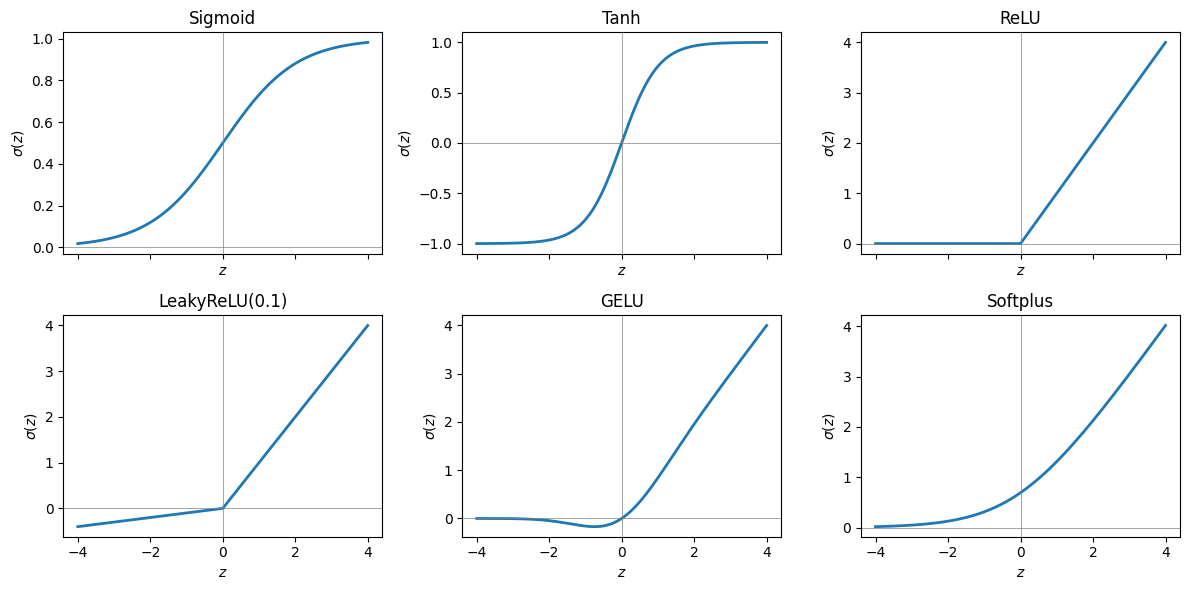

In [37]:
z = torch.linspace(-4, 4, 300)
acts = {"Sigmoid": nn.Sigmoid(), "Tanh": nn.Tanh(), "ReLU": nn.ReLU(),
        "LeakyReLU(0.1)": nn.LeakyReLU(0.1), "GELU": nn.GELU(), "Softplus": nn.Softplus()}

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (name, act) in zip(axes.flatten(), acts.items()):
    ax.plot(z, act(z), lw=2)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(name); ax.set_xlabel("$z$"); ax.set_ylabel(r"$\sigma(z)$")
fig.tight_layout(); plt.show()

### Stacking layers with `nn.Sequential`
The single-hidden-layer network
$$f(x) = \sum_{i=1}^{N} W^{(2)}_i\,\sigma(W^{(1)}_i x + b_i) + b^{(2)} , \tag{21}$$
with $\tanh$ as $\sigma$, is `Linear(1, N) → Tanh → Linear(N, 1)`. By the Universal Approximation Theorem (see the lecture), such a network can approximate any continuous function on an
interval when $N$ is large enough. The width, 16, is arbitrary.

The parameter count is $3N + 1$: the first layer has $N$ weights and $N$ biases, the second $N$ weights and 1 bias. In the code, `model.parameters()` yields
the trainable tensors of the model one after another, `named_parameters()` yields them together with their names, and `p.numel()` is the number of elements of
a tensor. `sum(p.numel() for p in model.parameters())` adds up `p.numel()` for every parameter tensor without first building a list.

In [38]:
torch.manual_seed(1)
N = 16
model = nn.Sequential(
    nn.Linear(1, N),     # W^(1), b      : x -> N hidden pre-activations
    nn.Tanh(),           # sigma, element-wise
    nn.Linear(N, 1),     # W^(2), b^(2)  : N hidden activations -> 1 output
)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("number of trainable parameters:", n_params, "= 3N + 1 =", 3 * N + 1)
for name, p in model.named_parameters():
    print(f"  {name:10s} {tuple(p.shape)}")

Sequential(
  (0): Linear(in_features=1, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
number of trainable parameters: 49 = 3N + 1 = 49
  0.weight   (16, 1)
  0.bias     (16,)
  2.weight   (1, 16)
  2.bias     (1,)


The untrained network is evaluated on a grid of 400 inputs (a batch of shape `(400, 1)`; range and number of points are arbitrary choices for the plot).

A `with` block switches a setting on for the indented lines only and restores it afterwards. Inside `with torch.no_grad():` PyTorch does not record the
operations needed to compute gradients, which saves memory and time when a network is only evaluated.

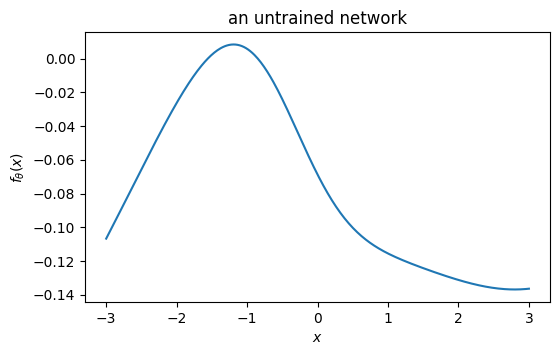

In [39]:
x = torch.linspace(-3, 3, 400)[:, None]       # shape (400, 1): batch of 1D inputs
with torch.no_grad():                         # we only evaluate; no gradients needed
    y = model(x)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x.squeeze(), y.squeeze())
ax.set_xlabel("$x$"); ax.set_ylabel(r"$f_\theta(x)$"); ax.set_title("an untrained network")
plt.show()

The curve is smooth, but its shape and its small values (here between about $-0.14$ and $0.01$) are determined only by the random initial values of the 49
parameters; another seed gives another curve. `.squeeze()` turns the shapes `(400, 1)` into `(400,)` for plotting. Fitting such a network to a given function
means changing its parameters until the curve follows the target: this is training.

### Drawing and summarising a network
The structure of the network above can be shown in three complementary ways: by our own drawing function, which shows every neuron and every
weight, and by the libraries `torchinfo` and `torchview`, which work on the level of layers and accept any PyTorch model.

`draw_network` is the drawing function used for network diagrams throughout the course. It draws a dense network as columns of
circles, one column per layer and one circle per neuron, and joins every circle with every circle of the next column by a thin grey line, one
line per weight. The height of a column grows with the logarithm of the layer size, so that a wide layer looks taller than a narrow one and a network
that compresses its input visibly narrows. A layer with more neurons than `max_nodes` is drawn with its first and last few neurons and a vertical
ellipsis in between; its true size is always written under the column. The colours follow one convention in all notebooks: grey for the data at the
input and at the output, blue for hidden layers, orange for a latent (bottleneck) layer and green for an additional input such as a class label.

To draw your own network, pass the list of layer sizes from the input to the output, for example `draw_network([784, 128, 64, 10])`, and, if you
wish, a list of names (`labels`) and of colours (`colors`) with one entry per column. An entry of `layer_sizes` can itself be a list, such as
`[16, 16]`, which stacks two blocks in one column; `groups` draws a bracket with a name above a range of columns, and `no_input` lists blocks that
receive no edges from the previous column. The function returns the matplotlib axes, so the figure can be changed further or saved with
`ax.figure.savefig(...)`. It needs only NumPy and matplotlib and therefore also runs in Colab. The comments in the code explain each step
(node positions, the truncation of large layers, the edges, the labels and the brackets), so that the function can be adapted to other diagrams.

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


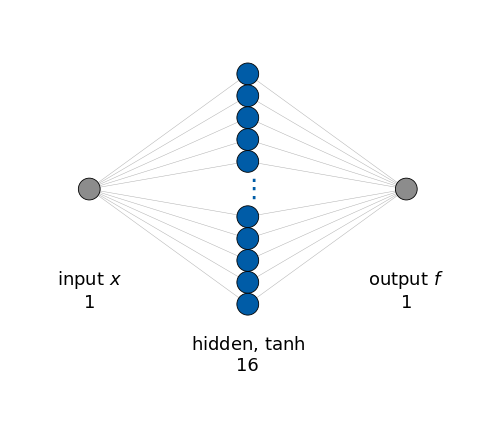

In [41]:
linear = [m for m in model.modules() if isinstance(m, nn.Linear)]   # the Linear layers of the model, in order
sizes = [linear[0].in_features] + [m.out_features for m in linear]   # layer sizes read from the model: [1, 16, 1]
n_from_sizes = sum(n_out * (n_in + 1) for n_in, n_out in zip(sizes[:-1], sizes[1:]))
assert n_from_sizes == n_params                                      # the drawing shows the network that was built
ax = draw_network(sizes, labels=["input $x$", r"hidden, $\tanh$", "output $f$"])
plt.show()

The library `torchinfo` prints a table of the layers. `torchinfo.summary(model, input_size=...)` passes a batch of zeros of the given shape
through the model and records, for every layer, the shape of its output and the number of its parameters; the lines at the bottom give the totals
and an estimate of the memory needed. The first number of `input_size` is the batch size: it appears as the first dimension of every output
shape and does not change the parameter counts. The library `torchview` passes the same kind of batch through the model and draws the layers as a
graph in which every box is one layer with the shapes of its input and output; with `expand_nested=True` a submodule that itself contains layers,
such as an `nn.Sequential` block called inside a larger model, is drawn as a frame around its layers. The graph is rendered by the program Graphviz to a PNG (Portable Network Graphics) file.

The three views serve different purposes. The neuron-level drawing explains what a dense layer is but is practical only for small dense networks.
The `torchinfo` table is the quickest check of shapes and parameter counts and the first thing to print when a model raises a shape error. The
`torchview` graph shows how the layers are connected, which matters as soon as the data flow is not a single chain, for example with skip
connections or several inputs.

In [42]:
import importlib.util, os, subprocess, sys
for package in ["torchinfo", "torchview"]:          # installed only if missing, e.g. in a fresh Colab session
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
import torchinfo
from torchview import draw_graph
from IPython.display import Image, display

info = torchinfo.summary(model, input_size=(400, 1), verbose=0)    # the batch of 400 inputs used for the plot above
print(info)
print("parameters: torchinfo", info.total_params, "  our count", n_params)
assert info.total_params == n_from_sizes                             # the drawing above agrees with the library

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [400, 1]                  --
├─Linear: 1-1                            [400, 16]                 32
├─Tanh: 1-2                              [400, 16]                 --
├─Linear: 1-3                            [400, 1]                  17
Total params: 49
Trainable params: 49
Non-trainable params: 0
Total mult-adds (M): 0.02
Input size (MB): 0.00
Forward/backward pass size (MB): 0.05
Params size (MB): 0.00
Estimated Total Size (MB): 0.06
parameters: torchinfo 49   our count 49


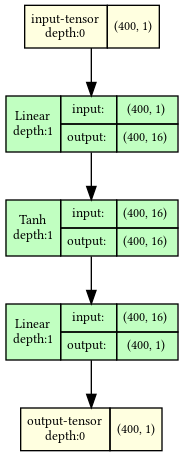

In [43]:
os.makedirs("figures", exist_ok=True)
graph = draw_graph(model, input_size=(400, 1), expand_nested=True)
png = graph.visual_graph.render("figures/lab003_sequential_graph", format="png", cleanup=True)   # Graphviz writes the PNG file
display(Image(png))

The parameters of the two `Linear` layers,
$$32 + 17 = 49 , \tag{22}$$
reproduce the count $3N + 1$; the activation `Tanh` has none. Our drawing shows what a dense layer is, a set of neurons connected to all neurons of the previous layer, but it becomes
unreadable for networks with thousands of neurons per layer or with layers that are not dense. The table and the graph show only layers and
shapes, and they work for every model, including the convolutional networks and networks with skip connections of later lectures.

<hr/>
## 7. Model classes

For anything non-trivial we define a class that inherits from `nn.Module`. Two methods are required. `__init__` creates the layers and parameters, and must always call `super().__init__()` first.
`forward(x)` describes the computation; the model is then called as `model(x)`, **not** `model.forward(x)`.
Parameters wrapped in `nn.Parameter` (and all parameters of sub-layers) are registered automatically.

Both rules have a reason. `super().__init__()` runs the `__init__` of `nn.Module`, which creates the internal lists in which parameters and sub-layers are
registered; assigning an `nn.Parameter` before this call fails with `AttributeError: cannot assign parameters before Module.__init__() call`. Calling `model(x)`
runs `forward` together with additional bookkeeping of PyTorch (so-called hooks), which a direct call of `forward` would skip.

Below, the Universal Approximation Theorem (UAT) ansatz is implemented explicitly — exactly the formula from the lecture. In `def __init__(self, N, activation=torch.tanh)` the argument `activation`
has a **default value**: it is used when the caller does not give this argument. A function such as `torch.tanh` can be passed and stored like any other object.

The initial values are chosen as follows. `W1` and `b` are drawn from the standard normal distribution. Neuron $i$ switches (its $\tanh$ changes sign) at
$$x_i^\ast = -b_i/W^{(1)}_i ; \tag{23}$$
with
`W1` and `b` of order one, most of these points (about 80 %) lie in $[-3, 3]$, the range of inputs of the plots, so most neurons are not saturated there.
The output bias `c` ($b^{(2)}$ above) only shifts $f$ up or down; there is no reason to start with a shift, so it starts at 0.

In [44]:
class UATNet(nn.Module):
    """f(x) = sum_i W2_i * sigma(W1_i * x + b_i) + c   (single hidden layer, N neurons)."""

    def __init__(self, N, activation=torch.tanh):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(N))        # input weights
        self.b = nn.Parameter(torch.randn(N))         # biases
        self.W2 = nn.Parameter(torch.randn(N) / N**0.5)  # output weights, scaled by 1/sqrt(N) (explained below)
        self.c = nn.Parameter(torch.zeros(1))         # output bias
        self.activation = activation

    def forward(self, x):                             # x: shape (B,) -> output (B,)
        hidden = self.activation(self.W1 * x[:, None] + self.b)   # (B, N) by broadcasting
        return hidden @ self.W2 + self.c

torch.manual_seed(0)
net = UATNet(N=8)
print(net)            # prints only sub-modules (layers); our parameters are listed separately:
print("parameters:", [(n, tuple(p.shape)) for n, p in net.named_parameters()])
x = torch.linspace(-3, 3, 200)    # shape (200,): this class takes a 1D tensor, nn.Sequential above needed shape (200, 1)
print("output shape:", net(x).shape)

UATNet()
parameters: [('W1', (8,)), ('b', (8,)), ('W2', (8,)), ('c', (1,))]
output shape: torch.Size([200])


The output weights are divided by $\sqrt N$, and the reason is statistical. The output is a sum of $N$ terms,
$$f(x) = \sum_{i=1}^{N} W^{(2)}_i h_i(x) + c, \qquad h_i = \tanh(\dots)\in[-1,1] . \tag{24}$$
If the $W^{(2)}_i$ are independent random numbers with mean 0 and variance $\sigma_W^2$, the terms are uncorrelated with mean zero and their variances add:
$$\mathrm{Var}\, f(x) = N\,\sigma_W^2\,\overline{h^2}, \qquad \text{standard deviation of } f \;\propto\; \sqrt{N}\,\sigma_W , \tag{25}$$
where
$$\overline{h^2} = \frac1N\sum_i h_i(x)^2 \le 1 \tag{26}$$
is the mean squared hidden activation (the variance is taken over random $W^{(2)}$ at fixed $x$, with vanishing $c$).
With unit $\sigma_W$ an untrained network with many neurons would produce outputs that grow like $\sqrt N$, far from the order-one values of typical targets.
With $\sigma_W$ of $1/\sqrt N$ the variance of the output is of order one for every $N$. The same rule, weights scaled by $1/\sqrt{n_{\rm in}}$ with $n_{\rm in}$ the number of
inputs of the layer, is the basis of the standard initialisations (LeCun, Xavier/Glorot), and `nn.Linear` uses it by default. The first layer has a single input, so `W1`
is not scaled. The standard deviation of $f$ over the inputs and 50 random initialisations is measured with and without the factor;
the 50 outputs of shape `(200,)` are joined by `torch.cat` into one vector of 10 000 values, of which `std()` computes the sample
standard deviation (normalised by the number of values minus one, which makes no difference for 10 000 values).

In [45]:
x_test = torch.linspace(-3, 3, 200)[:, None]                   # shape (200, 1)
print("   N   std of f, W2 ~ N(0, 1)   std of f, W2 ~ N(0, 1/N)")
for n_hidden in [1, 10, 100, 1000]:
    stds = {}
    for scaled in [False, True]:
        outputs = []
        for seed in range(50):                                 # 50 random networks
            torch.manual_seed(seed)
            W1, b1 = torch.randn(n_hidden), torch.randn(n_hidden)
            W2 = torch.randn(n_hidden) / (n_hidden**0.5 if scaled else 1.0)
            outputs.append(torch.tanh(x_test * W1 + b1) @ W2)  # (200,) for this network
        stds[scaled] = torch.cat(outputs).std().item()
    print(f"{n_hidden:5d}   {stds[False]:20.2f}   {stds[True]:22.2f}")

   N   std of f, W2 ~ N(0, 1)   std of f, W2 ~ N(0, 1/N)
    1                   0.67                     0.67
   10                   2.77                     0.87


  100                   7.52                     0.75


 1000                  21.90                     0.69


Without the factor the standard deviation grows by roughly a factor of 3 for every tenfold increase of $N$ (expected: $\sqrt{10}$, about 3.2; with 50 random
networks the estimate fluctuates); with the factor it stays of order one, independent of $N$.

A model can be moved to the GPU with `model.to(device)`, and switched to double precision with `model.double()`.
<hr/>
## 8. Summary
Tensors are NumPy arrays with two additions, GPU support and automatic differentiation. Their default dtype is `float32`; `float64` is used for precise physics.
`torch.from_numpy` shares memory with a NumPy array while `torch.tensor` copies it, and `.numpy()`, `.item()` and `.cpu()` lead back.
Among the shape operations, `reshape` and `view` change the shape while keeping the row-by-row order, `transpose` and `permute` reorder axes (producing non-contiguous views), `unsqueeze` and `squeeze` add or remove
axes of length 1, `cat` joins along an existing axis and `stack` along a new one; batched products are computed with `@` or `einsum`.
The device is chosen with `device = "cuda" if available else "cpu"`, and all tensors in one operation must be on the same device.
`nn.Linear(n_in, n_out)` computes $\mathbf W\mathbf z+\mathbf b$ on batches `(B, n_in)`, `nn.Sequential` stacks layers,
and our own models subclass `nn.Module` with `__init__` and `forward`. When a network is only evaluated, the computation goes inside `with torch.no_grad():`.
<hr/>
## 9. Exercises

### Exercise 1 — Ising chain energy in PyTorch
Implement the vectorised energy of a periodic Ising chain,
$$E = -\sum_{i=1}^{L} s_i s_{i+1}, \qquad s_{L+1} = s_1 , \tag{27}$$
in PyTorch (`torch.roll`, `torch.sum(..., dim=1)`).
Generate the random spins with `torch.randint(0, 2, (M, L)) * 2 - 1`. Run it on 100 000 configurations with chains of 64 spins and check the mean and standard deviation of the energy (about 0 and about $\sqrt{L}$).

#### Solution

In [46]:
torch.manual_seed(0)
M, L, J = 100_000, 64, 1.0

# torch.randint(0, 2, ...) gives 0 or 1; *2 - 1 maps them to -1 or +1.
# .float() converts integers to floats so that sums and std() work as expected.
spins = (torch.randint(0, 2, (M, L)) * 2 - 1).float()

# np.roll -> torch.roll, axis -> dims/dim (for readers who know NumPy)
E = -J * torch.sum(spins * torch.roll(spins, shifts=-1, dims=1), dim=1)

# .item() converts a one-element tensor to a Python number for printing
print(f"mean = {E.mean().item():.3f},  std = {E.std().item():.3f},  sqrt(L) = {L**0.5:.3f}")
# Why sqrt(L): with periodic boundaries the L products s_i s_{i+1} of independent random spins are pairwise independent
# (uncorrelated) numbers +-1 with mean 0 and variance 1, so their variances add: the sum has mean 0 and variance L,
# hence standard deviation sqrt(L).

mean = 0.050,  std = 7.986,  sqrt(L) = 8.000


### Exercise 2 — Tensor shapes in a multilayer network
Build `model = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))` — the classic network for MNIST (Modified National Institute of Standards and Technology database: 70 000 grey-scale images of handwritten digits 0–9, each of $28\times28$ pixels) from the next lecture.
1. Feed a random batch of 32 "images" of shape `(32, 28, 28)`. It fails; read the error message and fix the problem with `reshape`.
2. Print the shape of the output. What do the 10 numbers per image represent?
3. Count the parameters, on paper from
   $$P = \sum_l n_l(n_{l-1}+1) \tag{28}$$
   for layer sizes $n_0, n_1, \dots$, and with `sum(p.numel() ...)`.
4. The softmax
   $$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}} \tag{29}$$
   turns the 10 outputs $z_k$ into probabilities. Apply `torch.softmax(out, dim=1)` and check that each row sums to 1.

#### Solution

In [47]:
model = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
images = torch.rand(32, 28, 28)               # 32 random 28x28 "images", values uniform in [0, 1) like pixel intensities

# 1) The first layer expects input of shape (batch, 784). A (32, 28, 28) tensor is interpreted as
#    32*28 = 896 rows of length 28, which does not match 784 -> error.
try:
    model(images)
except RuntimeError as e:
    print("Error:", e)

# Fix: flatten every image into a vector of 28*28 = 784 numbers; with -1, PyTorch computes that size.
flat = images.reshape(32, -1)
print("flattened shape:", flat.shape)
out = model(flat)

# 2) One row per image, 10 numbers per row: one score (logit) per digit class 0..9
print("output shape:", out.shape)

# 3) Parameters: layer n_in -> n_out has n_out * n_in weights and n_out biases
by_hand = 128 * (784 + 1) + 64 * (128 + 1) + 10 * (64 + 1)
print("parameters:", sum(p.numel() for p in model.parameters()), " explicit formula:", by_hand)

# 4) Softmax over the class dimension (dim=1) turns the scores into probabilities: p_k = exp(z_k) / sum_j exp(z_j)
#    is positive and the p_k sum to 1. The unnormalised scores z_k that enter the softmax are called logits.
with torch.no_grad():                   # no gradient tracking needed here (otherwise the output shows grad_fn)
    probs = torch.softmax(out, dim=1)
print("row sums:", probs.sum(dim=1)[:5])

Error: mat1 and mat2 shapes cannot be multiplied (896x28 and 784x128)
flattened shape: torch.Size([32, 784])
output shape: torch.Size([32, 10])
parameters: 109386  explicit formula: 109386
row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


### Exercise 3 — Random networks of different depth
Using `nn.Sequential`, build networks with layer sizes $[1, W, \dots, W, 1]$, $\tanh$ activations, width 64 and depth (number of hidden layers) $1, 3, 10$.
For each depth draw 5 random initialisations and plot $f(x)$ on $[-5,5]$.
Do this twice: (a) with PyTorch's default initialisation, (b) with all weights redrawn from $\mathcal N(0, (3/\sqrt{n_\text{in}})^2)$, where $n_\text{in}$ is the number of inputs of the layer.
How does the shape of a random function change with depth in the two cases?
(The factor 3 is one choice among many; for $\tanh$ networks the boundary between the two kinds of behaviour shown by (a) and (b) lies at a factor of about 1,
and any factor well above 1 shows the effect of (b).)
*Hint:* build the list of layers in a loop and pass it as `nn.Sequential(*layers)`; `torch.nn.init.normal_(layer.weight, std=...)` redraws the weights of a layer.

#### Solution

default init      depth  1: range of f over [-5, 5] for the 5 networks: [0.9912 2.7868 0.471  1.1998 0.9899]
default init      depth  3: range of f over [-5, 5] for the 5 networks: [0.0978 0.1152 0.2639 0.3197 0.1088]
default init      depth 10: range of f over [-5, 5] for the 5 networks: [0.0015 0.0027 0.0035 0.0065 0.0054]


std 3/sqrt(n_in)  depth  1: range of f over [-5, 5] for the 5 networks: [ 1.1431  1.5322  3.401   5.2946 12.0745]
std 3/sqrt(n_in)  depth  3: range of f over [-5, 5] for the 5 networks: [ 4.3558  4.1454  3.6766 10.2046  6.8429]
std 3/sqrt(n_in)  depth 10: range of f over [-5, 5] for the 5 networks: [11.8048 10.9719  9.7572  8.4522 10.6725]


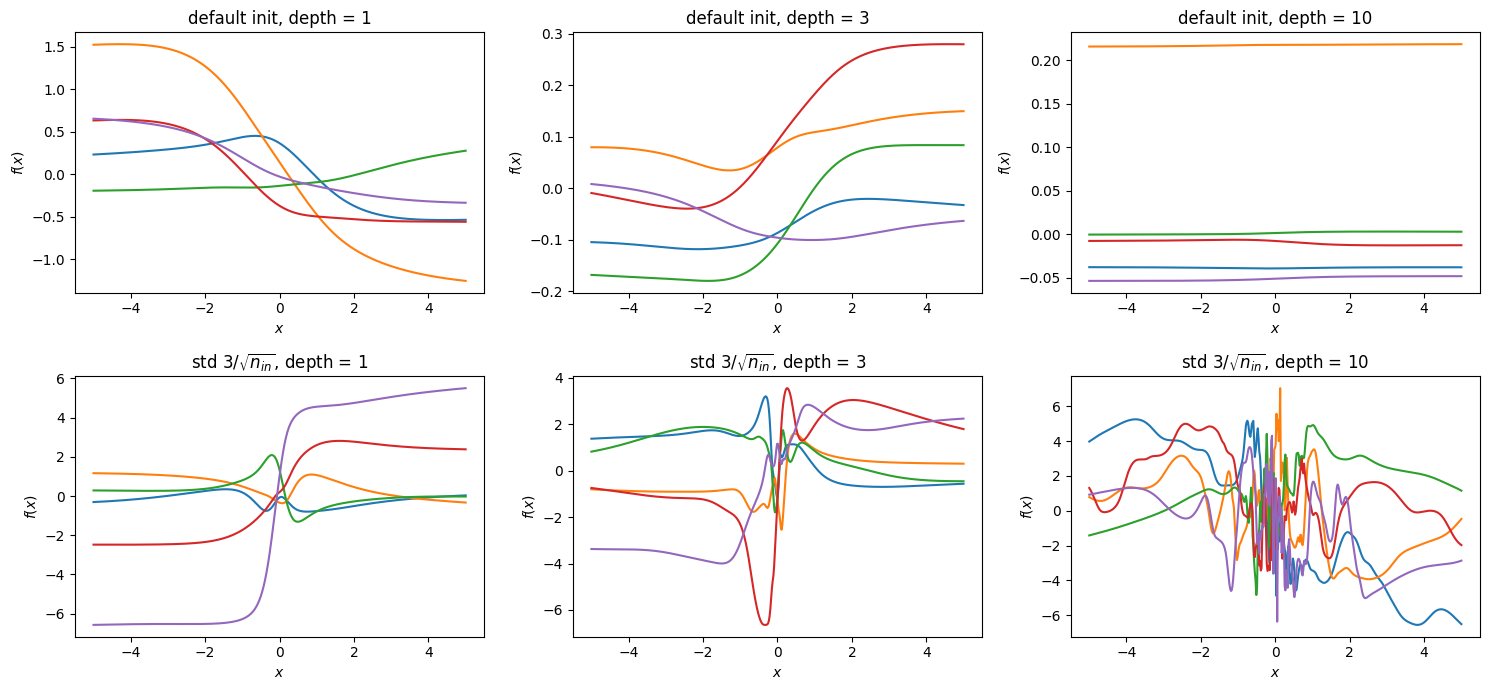

In [48]:
def make_mlp(depth, width=64, activation=nn.Tanh, weight_std_factor=None):
    """1 -> width -> ... -> width -> 1 network with `depth` hidden layers.
    weight_std_factor=None: PyTorch default initialisation; otherwise weights ~ N(0, (factor/sqrt(n_in))^2)."""
    layers = [nn.Linear(1, width), activation()]                  # activation is a class (nn.Tanh); activation() creates a layer object
    for _ in range(depth - 1):                                    # remaining hidden layers
        layers += [nn.Linear(width, width), activation()]
    layers.append(nn.Linear(width, 1))                            # linear output layer
    if weight_std_factor is not None:
        for layer in layers:
            if isinstance(layer, nn.Linear):                      # True if layer is an nn.Linear object; only these have weights
                n_in = layer.weight.shape[1]
                # the trailing underscore of normal_ marks an in-place operation: the existing weight tensor is overwritten
                nn.init.normal_(layer.weight, mean=0.0, std=weight_std_factor / n_in**0.5)
    return nn.Sequential(*layers)                                 # *layers passes the list elements as separate arguments

x = torch.linspace(-5, 5, 500)[:, None]                           # shape (500, 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (factor, row_name, plain_name) in enumerate([(None, "default init", "default init"),
                                                     (3.0, r"std $3/\sqrt{n_{in}}$", "std 3/sqrt(n_in)")]):
    for ax, depth in zip(axes[row], [1, 3, 10]):
        ranges = []
        for seed in range(5):
            torch.manual_seed(seed)                               # a different random network for each seed
            with torch.no_grad():                                 # evaluation only, no gradients
                y = make_mlp(depth, weight_std_factor=factor)(x).squeeze()
            ax.plot(x.squeeze(), y)
            ranges.append((y.max() - y.min()).item())
        ax.set_title(f"{row_name}, depth = {depth}")
        ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
        print(f"{plain_name:17s} depth {depth:2d}: range of f over [-5, 5] for the 5 networks:", np.round(ranges, 4))
fig.tight_layout(); plt.show()
# (a) Default initialisation draws weights uniformly from [-1/sqrt(n_in), 1/sqrt(n_in)] (variance 1/(3 n_in)).
#     Every tanh layer then shrinks the signal, and depth does NOT increase complexity: the outputs of the
#     10-layer networks vary by less than 1e-2 over the whole interval, i.e. they are almost constant.
# (b) With larger weights each layer stretches the signal and folds it through tanh; deep random networks
#     then become rapidly oscillating functions; the larger the factor, the more local maxima and minima
#     the deep networks have on [-5, 5].
# Depth can produce complicated functions, but only if the weights have a suitable scale; this is one
# reason why the initialisation of deep networks matters.

### Exercise 4 (advanced) — A custom layer
Write an `nn.Module` called `GaussianRBF` implementing
$$f(x) = \sum_{i=1}^{N} a_i\, \exp\!\big(-(x-\mu_i)^2 / (2 s_i^2)\big) \tag{30}$$
with trainable $a_i, \mu_i, s_i$ (`nn.Parameter`). Initialise $\mu_i$ on a uniform grid on $[-3,3]$, all $s_i$ at 0.5 and $a_i$ drawn from $\mathcal N(0,1)$.
Plot the output and the individual Gaussians for 6 Gaussians. (Radial-basis-function networks are also universal approximators.)

#### Solution

parameters: [('a', (6,)), ('mu', (6,)), ('s', (6,))]


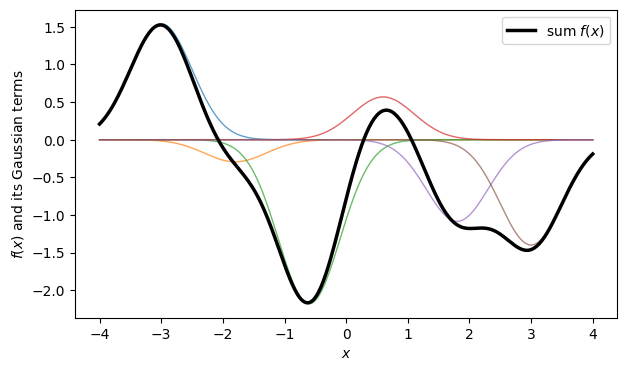

In [49]:
class GaussianRBF(nn.Module):
    """f(x) = sum_i a_i exp(-(x - mu_i)^2 / (2 s_i^2)) with trainable a, mu, s."""

    def __init__(self, N):
        super().__init__()
        # nn.Parameter registers the tensor as a trainable parameter of the module
        self.a = nn.Parameter(torch.randn(N))                 # amplitudes
        self.mu = nn.Parameter(torch.linspace(-3, 3, N))      # centres on a uniform grid
        self.s = nn.Parameter(0.5 * torch.ones(N))            # widths; for N = 6 the centres are 1.2 apart, so neighbouring
                                                              # Gaussians of width 0.5 overlap and their sum is a smooth curve

    def basis(self, x):
        """The N Gaussians evaluated at all points: shape (B, N)."""
        return torch.exp(-(x[:, None] - self.mu)**2 / (2 * self.s**2))

    def forward(self, x):
        return self.basis(x) @ self.a                         # weighted sum -> shape (B,)

torch.manual_seed(0)
rbf = GaussianRBF(6)
print("parameters:", [(name, tuple(p.shape)) for name, p in rbf.named_parameters()])

x = torch.linspace(-4, 4, 400)
with torch.no_grad():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(x, rbf.basis(x) * rbf.a, lw=1, alpha=0.7)        # (400, 6): ax.plot draws one curve per column = one weighted Gaussian
    ax.plot(x, rbf(x), "k", lw=2.5, label="sum $f(x)$")
    ax.legend(); ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$ and its Gaussian terms"); plt.show()

### Exercise 5 — einsum strings
1. Without running code, write down the shape of the result and the formula for: `"ij,jk,kl->il"` with shapes $(2,3),(3,4),(4,5)$; `"bij->bj"` with $(6,3,4)$;
   `"ij,kl->ijkl"` with $(2,3),(4,5)$; `"bii->b"` with $(6,3,3)$. Then check with code.
2. Write `einsum` strings for: (a) the sum of squares
   $$S = \sum_i u_i^2 ; \tag{31}$$
   (b) the matrix $A^{T}A$; (c) for a batch of matrices $A_b$ of shape $(B, n, n)$, the traces $\mathrm{tr}\,A_b$;
   (d) the quadratic form
   $$q_b = \sum_{ij} x_{bi} Q_{ij} x_{bj} \tag{32}$$
   for a batch of vectors $x_b$. Verify each against a computation without `einsum`.
3. Write a function `quadratic_form(x, Q)` that computes
   $$q = \sum_{ij} x_i Q_{ij} x_j \tag{33}$$
   for every vector along the **last** axis of `x`, whatever the number of
   batch axes in front (use `...`). Test it with `x` of shapes `(3,)`, `(6, 3)` and `(2, 6, 3)`.

#### Solution

In [50]:
torch.manual_seed(5)
# 1) shapes and formulas
a, b, c = torch.randn(2, 3), torch.randn(3, 4), torch.randn(4, 5)
r1 = torch.einsum("ij,jk,kl->il", a, b, c)      # r_il = sum_jk a_ij b_jk c_kl = (a @ b @ c)_il, shape (2, 5)
print("ij,jk,kl->il :", tuple(r1.shape), " equals a @ b @ c:", torch.allclose(r1, a @ b @ c, atol=1e-6))
t = torch.randn(6, 3, 4)
r2 = torch.einsum("bij->bj", t)                 # r_bj = sum_i t_bij, shape (6, 4)
print("bij->bj      :", tuple(r2.shape), " equals t.sum(dim=1):", torch.allclose(r2, t.sum(dim=1)))
r3 = torch.einsum("ij,kl->ijkl", a, c)          # r_ijkl = a_ij c_kl (nothing summed), shape (2, 3, 4, 5)
print("ij,kl->ijkl  :", tuple(r3.shape), " element check:", torch.allclose(r3[1, 2, 3, 4], a[1, 2] * c[3, 4]))
sq = torch.randn(6, 3, 3)
r4 = torch.einsum("bii->b", sq)                 # r_b = sum_i sq_bii (trace of every matrix), shape (6,)
print("bii->b       :", tuple(r4.shape), " equals traces:", torch.allclose(r4, sq.diagonal(dim1=1, dim2=2).sum(dim=1)))

# 2) writing strings
u = torch.randn(5)
A43 = torch.randn(4, 3)
As = torch.randn(6, 3, 3)
xb, Q = torch.randn(6, 3), torch.randn(3, 3)
print("(a) i,i->        :", torch.allclose(torch.einsum("i,i->", u, u), (u**2).sum()))
print("(b) ki,kj->ij    :", torch.allclose(torch.einsum("ki,kj->ij", A43, A43), A43.T @ A43, atol=1e-6))
print("(c) bii->b       :", torch.allclose(torch.einsum("bii->b", As), torch.stack([torch.trace(m) for m in As])))
print("(d) bi,ij,bj->b  :", torch.allclose(torch.einsum("bi,ij,bj->b", xb, Q, xb),
                                           ((xb @ Q) * xb).sum(dim=1), atol=1e-6))

# 3) one string for any number of batch axes: '...' stands for all axes before the last one
def quadratic_form(x, Q):
    return torch.einsum("...i,ij,...j->...", x, Q, x)

for shape in [(3,), (6, 3), (2, 6, 3)]:
    xs = torch.randn(shape)
    reference = ((xs @ Q) * xs).sum(dim=-1)
    print(f"quadratic_form for x of shape {str(shape):10s}: result shape {str(tuple(quadratic_form(xs, Q).shape)):8s}"
          f" agrees: {torch.allclose(quadratic_form(xs, Q), reference, atol=1e-5)}")

ij,jk,kl->il : (2, 5)  equals a @ b @ c: True
bij->bj      : (6, 4)  equals t.sum(dim=1): True
ij,kl->ijkl  : (2, 3, 4, 5)  element check: True
bii->b       : (6,)  equals traces: True
(a) i,i->        : True
(b) ki,kj->ij    : True
(c) bii->b       : True
(d) bi,ij,bj->b  : True
quadratic_form for x of shape (3,)      : result shape ()       agrees: True
quadratic_form for x of shape (6, 3)    : result shape (6,)     agrees: True
quadratic_form for x of shape (2, 6, 3) : result shape (2, 6)   agrees: True


### Exercise 6 — Predicting shapes
For `t = torch.arange(24).reshape(2, 3, 4)`, first predict on paper, then check with code:
1. the shapes of `t.reshape(4, -1)`, `t.transpose(0, 2)`, `t.permute(1, 2, 0)`, `t.flatten(1)`, `t.unsqueeze(1)`, `t[:, None, :, None]`;
2. the value of `t.permute(1, 2, 0)[2, 3, 1]`;
3. which of the results in 1. are contiguous;
4. whether `t.transpose(0, 2).view(-1)` works.

#### Solution

In [51]:
t = torch.arange(24).reshape(2, 3, 4)

# 1) and 3): shapes and contiguity
results = {
    "t.reshape(4, -1)": t.reshape(4, -1),            # 24 / 4 = 6  -> (4, 6)
    "t.transpose(0, 2)": t.transpose(0, 2),          # axes 0 and 2 swapped -> (4, 3, 2)
    "t.permute(1, 2, 0)": t.permute(1, 2, 0),        # old axes (1, 2, 0) -> (3, 4, 2)
    "t.flatten(1)": t.flatten(1),                    # axes 1 and 2 merged -> (2, 12)
    "t.unsqueeze(1)": t.unsqueeze(1),                # new axis at position 1 -> (2, 1, 3, 4)
    "t[:, None, :, None]": t[:, None, :, None],      # new axes at positions 1 and 3 -> (2, 1, 3, 1, 4)
}
for name, r in results.items():
    print(f"{name:22s} shape {str(tuple(r.shape)):16s} contiguous: {r.is_contiguous()}")
# reshape, flatten and inserting axes of length 1 keep the row-by-row order of the elements (contiguous);
# transpose and permute only change the strides, so the elements are no longer stored row by row

# 2) element [2, 3, 1] of t.permute(1, 2, 0) is element [1, 2, 3] of t (old axis 0 is now last)
print("t.permute(1, 2, 0)[2, 3, 1] =", t.permute(1, 2, 0)[2, 3, 1].item(), "= t[1, 2, 3] =", t[1, 2, 3].item(),
      "= 1*12 + 2*4 + 3")

# 4) view on a non-contiguous tensor
try:
    t.transpose(0, 2).view(-1)
except RuntimeError as e:
    print("view fails:", e)

t.reshape(4, -1)       shape (4, 6)           contiguous: True
t.transpose(0, 2)      shape (4, 3, 2)        contiguous: False
t.permute(1, 2, 0)     shape (3, 4, 2)        contiguous: False
t.flatten(1)           shape (2, 12)          contiguous: True
t.unsqueeze(1)         shape (2, 1, 3, 4)     contiguous: True
t[:, None, :, None]    shape (2, 1, 3, 1, 4)  contiguous: True
t.permute(1, 2, 0)[2, 3, 1] = 23 = t[1, 2, 3] = 23 = 1*12 + 2*4 + 3
view fails: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.


### Exercise 7 — A batch of rotations
1. For 6 angles
   $$\varphi_b = b\pi/6 \tag{34}$$
   build a tensor `R` of shape `(B, 2, 2)` of rotation matrices
   $\begin{pmatrix}\cos\varphi & -\sin\varphi\\ \sin\varphi & \cos\varphi\end{pmatrix}$ using `torch.stack` (no loop).
2. Rotate the unit vector $(1, 0)$ by every angle in three ways: with `@` and `unsqueeze`/`squeeze`, with `torch.einsum`, and with `torch.bmm`
   (which multiplies batches of matrices). Check that the results agree and plot the rotated vectors.
3. Verify
   $$R^{T}R = 1 \tag{35}$$
   for all matrices at once.

#### Solution

R shape: (6, 2, 2)
all three agree: True


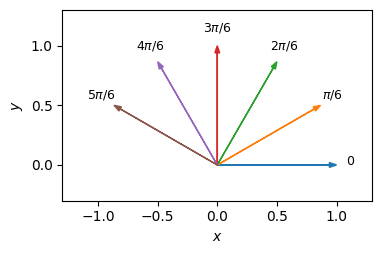

max |R^T R - 1|: 0.0


In [52]:
n_rot = 6
phi = torch.arange(n_rot) * torch.pi / 6                  # shape (n_rot,)
c, s = torch.cos(phi), torch.sin(phi)
# 1) stack the four entries: first the two rows (each of shape (B, 2)), then the rows into matrices
row1 = torch.stack([c, -s], dim=1)                        # (n_rot, 2)
row2 = torch.stack([s, c], dim=1)                         # (n_rot, 2)
R = torch.stack([row1, row2], dim=1)                      # (n_rot, 2, 2): R[b] = [[c, -s], [s, c]]
print("R shape:", tuple(R.shape))

# 2) rotate the unit vector e_x by every angle
e_x = torch.tensor([1.0, 0.0]).expand(n_rot, 2)          # the same vector for every rotation (expand adds the batch axis)
rot1 = (R @ e_x.unsqueeze(2)).squeeze(2)                  # (n_rot, 2, 2) @ (n_rot, 2, 1) -> (n_rot, 2, 1) -> (n_rot, 2)
rot2 = torch.einsum("bij,bj->bi", R, e_x)
rot3 = torch.bmm(R, e_x.unsqueeze(2)).squeeze(2)
print("all three agree:", torch.allclose(rot1, rot2) and torch.allclose(rot1, rot3))

fig, ax = plt.subplots(figsize=(4, 4))
angle_labels = ["$0$", r"$\pi/6$", r"$2\pi/6$", r"$3\pi/6$", r"$4\pi/6$", r"$5\pi/6$"]
for b in range(n_rot):
    ax.arrow(0, 0, rot1[b, 0].item(), rot1[b, 1].item(), head_width=0.04, length_includes_head=True, color=f"C{b}")
    ax.text(1.12 * rot1[b, 0].item(), 1.12 * rot1[b, 1].item(), angle_labels[b], ha="center", fontsize=9)
ax.set_xlim(-1.3, 1.3); ax.set_ylim(-0.3, 1.3); ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
plt.show()

# 3) R^T R for all rotations at once: transpose the last two axes
RtR = R.transpose(1, 2) @ R                               # (n_rot, 2, 2)
print("max |R^T R - 1|:", (RtR - torch.eye(2)).abs().max().item())

### Exercise 8 — Applying a layer to every time step
A batch of 8 time series ($B$), each with 50 time steps ($T$) and 3 measured quantities per step ($F$), is stored as a tensor of shape `(B, T, F)`.
1. Apply `nn.Linear(3, 5)` to every time step by reshaping to `(B*T, F)`, applying the layer, and reshaping back to `(B, T, 5)`.
2. Apply the layer directly to the `(B, T, F)` tensor and compare: `nn.Linear` acts on the **last** axis and treats all other axes as batch axes.
3. What goes wrong if the tensor is stored as `(B, F, T)` instead? Fix it with `transpose`.

#### Solution

In [53]:
n_series, T, F = 8, 50, 3
torch.manual_seed(0)
series = torch.randn(n_series, T, F)
lin = nn.Linear(F, 5)

# 1) merge batch and time axes, apply the layer, split them again
out1 = lin(series.reshape(n_series * T, F)).reshape(n_series, T, 5)
# 2) directly: Linear acts on the last axis
out2 = lin(series)
print("shapes:", tuple(out1.shape), tuple(out2.shape), "  agree:", torch.allclose(out1, out2))

# 3) features before time: the last axis has length T = 50, not F = 3
series_ft = series.transpose(1, 2)                        # (B, F, T)
try:
    lin(series_ft)
except RuntimeError as e:
    print("RuntimeError:", e)
    # Linear merges all leading axes into one batch axis, (8 * 3) x 50 = 24 x 50, and multiplies it with W^T, which is 3 x 5
    # (the stored weight has shape (5, 3)): the inner dimensions 50 and 3 do not match
out3 = lin(series_ft.transpose(1, 2))                     # back to (B, T, F) before the layer
print("after transposing back:", tuple(out3.shape), "  agrees:", torch.allclose(out3, out1))

shapes: (8, 50, 5) (8, 50, 5)   agree: True
RuntimeError: mat1 and mat2 shapes cannot be multiplied (24x50 and 3x5)
after transposing back: (8, 50, 5)   agrees: True
